# 277. SCOPe40 family and superfamily sensitivity with kmerseek 0.4: 19 alphabets, k_min to k_max, six settings

**Data.** The SCOPe40 sweep of
[PR 107](https://github.com/seanome/2024-kmerseek-analysis/pull/107)
(`nextflow-runs/scope40-alphabet-ksize-v040`), run on Sherlock from 2026-10-10 10:36 to
2026-10-12 07:53 (head job 46668151), image `olgabot/kmerseek:0.4.0-rc5` (kmerseek 0.4.0).
Query set and target database are the same: the 15_177 SCOPe 2.08 domains at 40% identity
(`astral-scopedom-seqres-gd-sel-gs-bib-40-2.08.fa`), searched all against all. 19 alphabets,
each at every k from its k_min to its k_max in
[notebook 274](https://github.com/seanome/2024-kmerseek-analysis/pull/101) (229
alphabet-ksize pairs), each with six settings: `exact` (no extension) and extension with
mismatch penalty C at `c_min`, 1.1 x `c_min`, `c_opt`, `c_max` and C = 2. The PR body defines
each C. That is 1_358 searches; all 1_358 finished. The table read here is the pipeline's
`scope40_v040_auc.tsv`, one row per search, score column and SCOP level.

**What is measured.** For each query, hits are ranked by one kmerseek score column.
Sensitivity is the share of that query's true positives ranked above its first false positive,
with FoldSeek's rule: a hit in a different fold is a false positive, and a hit in the same fold
but a different superfamily is ignored. The AUC is the mean of that share over queries
(higher is better; 1 means every true positive ranks above every false positive, 0 means none
does). This notebook uses `auc_ref`: the AUC over FoldSeek's 5_713 SCOPe40 queries, where a
query kmerseek returns no hit for counts as 0, so every tool has the same denominator.
Family level: true positive = same SCOP family. Superfamily level: same superfamily,
different family.

**Other tools, same 5_713 queries** (TEA paper's `.rocx` files in `data/tea_scope40_rocx_files`):
FoldSeek (structure) and MMseqs2 (sequence).

**Decisions this notebook makes.** These were written after a first look at the 15 highest
family AUCs, not before any result.

1. *Which score column the SCOPe40 figures rank by.* The column with the highest median family
   AUC across the extension searches, provided that tied scores do not move its AUC (median
   difference between the two tie orders is 0).
2. *Which mismatch penalty C to run by default.* The setting that gives the best family AUC for
   the most alphabets.
3. *Whether the k range must go lower.* If the best k sits at the alphabet's k_min for most
   alphabets, sensitivity may still be rising at the bottom of the range, and the sweep has to
   extend below k_min before any "best k" is quoted. Section 6 runs that test.
4. *Whether SCOPe40 supports the hydrophobic-polar (HP) alphabets.* If the best HP family AUC
   reaches half of MMseqs2's, SCOPe40 goes in the paper as support for HP; otherwise the HP
   case is made on the domain benchmarks, and SCOPe40 is reported for protein20 and the
   larger alphabets only.

In [1]:
import hashlib
import os
import re
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

import pubfig as pf
import scope_kmerseek_utils as su

pf.use_style()
pl.Config.set_tbl_rows(60)
pl.Config.set_tbl_cols(20)
pl.Config.set_tbl_width_chars(200)
pl.Config.set_float_precision(3)

AUC_TSV = Path(
    os.environ.get(
        "NB277_AUC_TSV",
        Path.home()
        / "data/scope/results-scope40-alphabet-ksize-v040/scope40_v040_auc.tsv",
    )
)
FIG_DIR = Path("../figures")
FIG_STEM = "277_scope40_kmerseek_v040"
LEVELS = ["family", "superfamily"]
EXTENSION_SETTINGS = ["c_min", "c_min_x1.1", "c_opt", "c_max", "c2"]
SETTINGS = ["exact"] + EXTENSION_SETTINGS
SETTING_LABEL = {
    "exact": "exact (no extension)",
    "c_min": "C = c_min",
    "c_min_x1.1": "C = 1.1 x c_min",
    "c_opt": "C = c_opt",
    "c_max": "C = c_max",
    "c2": "C = 2",
}
SETTING_COLOUR = {
    "exact": pf.OKABE_ITO["black"],
    "c_min": pf.OKABE_ITO["sky_blue"],
    "c_min_x1.1": pf.OKABE_ITO["blue"],
    "c_opt": pf.OKABE_ITO["bluish_green"],
    "c_max": pf.OKABE_ITO["vermillion"],
    "c2": pf.OKABE_ITO["orange"],
}
TOOL_STYLE = {  # other tools: vertical lines, never a colour used by a kmerseek setting
    "FoldSeek": dict(color=pf.GREY, ls="-", lw=1),
    "MMseqs2": dict(color=pf.GREY, ls="--", lw=1),
}
TOOL_ROCX = {"FoldSeek": "foldseek.rocx", "MMseqs2": "mmseqs.rocx"}

print(AUC_TSV)
print("sha256", hashlib.sha256(AUC_TSV.read_bytes()).hexdigest())
auc = pl.read_csv(AUC_TSV, separator="\t")
print(auc.shape)

/Users/olga/data/scope/results-scope40-alphabet-ksize-v040/scope40_v040_auc.tsv
sha256 c9a30b83d6c0a064b79f629c0fe921d6366d3b14b9d801cb06101077319101af
(55008, 19)


In [2]:
def alphabet_size(name: str) -> int:
    """Number of letters, the trailing number of the alphabet name (hp_thomas_dill2 -> 2)."""
    return int(re.search(r"(\d+)$", name).group(1))


def size_group(n: int) -> str:
    """Alphabet size group used to order every alphabet axis."""
    if n <= 3:
        return "2-3 letters"
    if n <= 8:
        return "4-8 letters"
    if n <= 18:
        return "12-18 letters"
    return "20 letters"


GROUP_ORDER = ["2-3 letters", "4-8 letters", "12-18 letters", "20 letters"]
ALPHABETS = sorted(
    auc["alphabet"].unique(),
    key=lambda a: (
        GROUP_ORDER.index(size_group(alphabet_size(a))),
        alphabet_size(a),
        a,
    ),
)


def alphabet_positions(alphabets, gap=0.8):
    """y position per alphabet, with a blank gap between size groups (top to bottom)."""
    pos, y, prev = {}, 0.0, None
    for a in alphabets:
        g = size_group(alphabet_size(a))
        if prev is not None and g != prev:
            y += gap
        pos[a] = y
        y += 1
        prev = g
    return pos


def alphabet_axis(ax, pos):
    """Alphabet names on y, grouped by size, guide lines from each tick across the panel."""
    ax.set_yticks(list(pos.values()), list(pos.keys()))
    ax.set_ylim(max(pos.values()) + 0.7, -0.7)
    for y in pos.values():
        ax.axhline(y, color="0.9", lw=0.3, zorder=0)


ks = (
    auc.select("alphabet", "ksize")
    .unique()
    .group_by("alphabet")
    .agg(
        pl.col("ksize").min().alias("k_min"),
        pl.col("ksize").max().alias("k_max"),
        pl.len().alias("n_ksizes"),
    )
)
print(
    ks.sort(pl.col("alphabet").replace_strict({a: i for i, a in enumerate(ALPHABETS)}))
)

shape: (19, 4)
┌──────────────────────────┬───────┬───────┬──────────┐
│ alphabet                 ┆ k_min ┆ k_max ┆ n_ksizes │
│ ---                      ┆ ---   ┆ ---   ┆ ---      │
│ str                      ┆ i64   ┆ i64   ┆ u32      │
╞══════════════════════════╪═══════╪═══════╪══════════╡
│ hp_kyte_doolittle2       ┆ 19    ┆ 39    ┆ 21       │
│ hp_lehninger2            ┆ 17    ┆ 30    ┆ 14       │
│ hp_lehninger_c_nonpolar2 ┆ 17    ┆ 31    ┆ 15       │
│ hp_pbotc_1st_ed2         ┆ 17    ┆ 30    ┆ 14       │
│ hp_thomas_dill2          ┆ 18    ┆ 36    ┆ 19       │
│ hp_thomas_dill_no_c2     ┆ 18    ┆ 39    ┆ 22       │
│ hp_lehninger_hpc3        ┆ 17    ┆ 29    ┆ 13       │
│ gbmr4                    ┆ 13    ┆ 28    ┆ 16       │
│ polarity4                ┆ 11    ┆ 25    ┆ 15       │
│ wwmj5                    ┆ 9     ┆ 15    ┆ 7        │
│ dayhoff6                 ┆ 8     ┆ 18    ┆ 11       │
│ gbmr7                    ┆ 13    ┆ 35    ┆ 23       │
│ funcgroups8              ┆ 7   

In [3]:
# Other tools on the same 5_713 FoldSeek queries, with the same AUC function the pipeline uses.
ref_queries = set(su.load_rocx_file(su.TEA_DIR / "foldseek.rocx")["NAME"])
tool_rows = []
for tool, fname in TOOL_ROCX.items():
    r = su.rocx_restrict(su.load_rocx_file(su.TEA_DIR / fname), ref_queries)
    for short, level in [("FAM", "family"), ("SFAM", "superfamily"), ("FOLD", "fold")]:
        tool_rows.append(
            {
                "tool": tool,
                "level": level,
                "auc_ref": float(su.sensitivity_stats(r, short)[2]),
                "n_queries_ref": r.height,
            }
        )
tools = pl.DataFrame(tool_rows)
TOOL_AUC = {(r["tool"], r["level"]): r["auc_ref"] for r in tools.iter_rows(named=True)}
print(tools)

shape: (6, 4)
┌──────────┬─────────────┬─────────┬───────────────┐
│ tool     ┆ level       ┆ auc_ref ┆ n_queries_ref │
│ ---      ┆ ---         ┆ ---     ┆ ---           │
│ str      ┆ str         ┆ f64     ┆ i64           │
╞══════════╪═════════════╪═════════╪═══════════════╡
│ FoldSeek ┆ family      ┆ 0.817   ┆ 5713          │
│ FoldSeek ┆ superfamily ┆ 0.574   ┆ 5713          │
│ FoldSeek ┆ fold        ┆ 0.102   ┆ 5713          │
│ MMseqs2  ┆ family      ┆ 0.403   ┆ 5713          │
│ MMseqs2  ┆ superfamily ┆ 0.172   ┆ 5713          │
│ MMseqs2  ┆ fold        ┆ 0.001   ┆ 5713          │
└──────────┴─────────────┴─────────┴───────────────┘


## 1. Which searches returned a usable result

Each search has one status per score column. `ok`: the column ranked the hits and has an AUC.
`nofit`: kmerseek refused the extension search because it could not fit the E-value
statistics for that alphabet, k and C; the search returned nothing, so it has no AUC (it is not
counted as 0 here). `constant`: the column has a single value for every hit, so it cannot rank;
for `exact` searches this is always `region_evalue`, `region_ka_bits` and `region_n_chained`,
which only extension fills in.

The figure shows, for each alphabet and setting, the share of that alphabet's k-sizes where
kmerseek returned hits. A pale square means most k-sizes were refused. `funcgroups8` has no
`c_opt` or `c_max` (no measured class agreement for it), drawn as a grey cross.

Searches with hits / searches run, per alphabet and setting
shape: (19, 7)
┌──────────────────────────┬───────┬───────┬────────────┬───────┬───────┬───────┐
│ alphabet                 ┆ exact ┆ c_min ┆ c_min_x1.1 ┆ c_opt ┆ c_max ┆ c2    │
│ ---                      ┆ ---   ┆ ---   ┆ ---        ┆ ---   ┆ ---   ┆ ---   │
│ str                      ┆ str   ┆ str   ┆ str        ┆ str   ┆ str   ┆ str   │
╞══════════════════════════╪═══════╪═══════╪════════════╪═══════╪═══════╪═══════╡
│ hp_kyte_doolittle2       ┆ 21/21 ┆ 10/21 ┆ 11/21      ┆ 10/21 ┆ 11/21 ┆ 11/21 │
│ hp_lehninger2            ┆ 14/14 ┆ 5/14  ┆ 8/14       ┆ 11/14 ┆ 11/14 ┆ 12/14 │
│ hp_lehninger_c_nonpolar2 ┆ 15/15 ┆ 6/15  ┆ 8/15       ┆ 11/15 ┆ 11/15 ┆ 12/15 │
│ hp_pbotc_1st_ed2         ┆ 14/14 ┆ 5/14  ┆ 8/14       ┆ 11/14 ┆ 11/14 ┆ 11/14 │
│ hp_thomas_dill2          ┆ 19/19 ┆ 7/19  ┆ 9/19       ┆ 10/19 ┆ 10/19 ┆ 10/19 │
│ hp_thomas_dill_no_c2     ┆ 22/22 ┆ 8/22  ┆ 8/22       ┆ 11/22 ┆ 11/22 ┆ 11/22 │
│ hp_lehninger_hpc3    

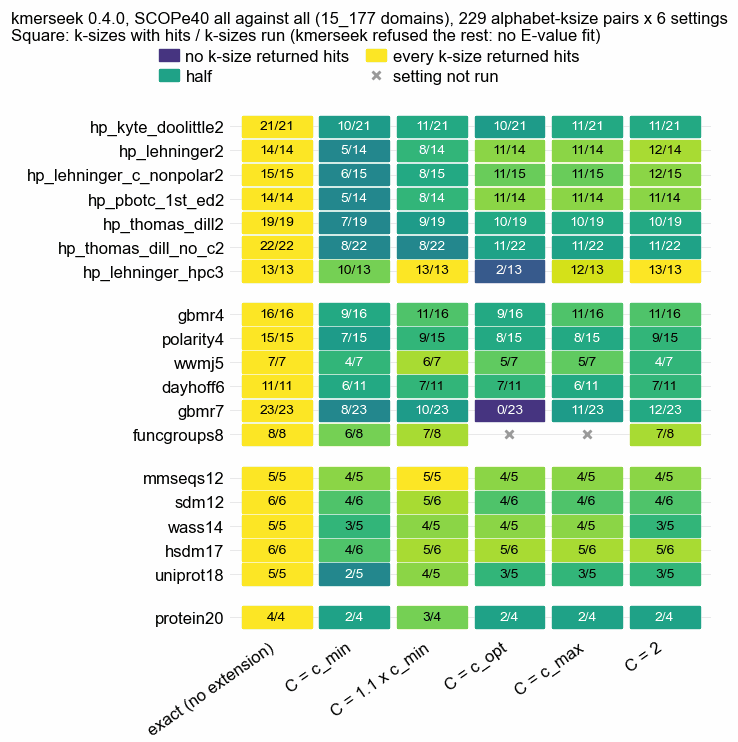

In [4]:
search = auc.group_by("alphabet", "ksize", "setting").agg(
    (pl.col("status") == "nofit").any().alias("nofit")
)
fit_share = (
    search.group_by("alphabet", "setting")
    .agg(pl.len().alias("n_ksizes"), (~pl.col("nofit")).sum().alias("n_fit"))
    .with_columns((pl.col("n_fit") / pl.col("n_ksizes")).alias("share_fit"))
)
wide = (
    fit_share.with_columns(
        (pl.col("n_fit").cast(str) + "/" + pl.col("n_ksizes").cast(str)).alias("fit")
    )
    .pivot(on="setting", index="alphabet", values="fit")
    .select(["alphabet"] + SETTINGS)
)
print("Searches with hits / searches run, per alphabet and setting")
print(
    wide.sort(
        pl.col("alphabet").replace_strict({a: i for i, a in enumerate(ALPHABETS)})
    )
)
print(
    search.group_by("setting")
    .agg(pl.len().alias("searches"), pl.col("nofit").sum().alias("nofit"))
    .sort("setting")
)

pos = alphabet_positions(ALPHABETS)
fig, ax = pf.figure(pf.ONE_COLUMN_MM, 95)
cmap = plt.get_cmap("viridis")
share = {(r["alphabet"], r["setting"]): r for r in fit_share.iter_rows(named=True)}
for j, s in enumerate(SETTINGS):
    for a, y in pos.items():
        r = share.get((a, s))
        if r is None:
            ax.plot(j, y, marker="x", color=pf.GREY, ms=3, label="setting not run")
            continue
        ax.add_patch(
            plt.Rectangle(
                (j - 0.45, y - 0.45), 0.9, 0.9, color=cmap(0.15 + 0.85 * r["share_fit"])
            )
        )
        ax.text(
            j,
            y,
            f"{r['n_fit']}/{r['n_ksizes']}",
            ha="center",
            va="center",
            fontsize=5,
            color="white" if r["share_fit"] < 0.6 else "black",
        )
ax.set_xlim(-0.6, len(SETTINGS) - 0.4)
ax.set_xticks(
    range(len(SETTINGS)), [SETTING_LABEL[s] for s in SETTINGS], rotation=35, ha="right"
)
alphabet_axis(ax, pos)
ax.spines[["left", "bottom"]].set_visible(False)
ax.tick_params(length=0)
handles = [
    plt.Rectangle((0, 0), 1, 1, color=cmap(0.15 + 0.85 * v)) for v in (0, 0.5, 1)
]
handles.append(plt.Line2D([], [], marker="x", ls="", color=pf.GREY, ms=3))
fig.legend(
    handles,
    [
        "no k-size returned hits",
        "half",
        "every k-size returned hits",
        "setting not run",
    ],
    loc="outside upper center",
    ncol=2,
    title="kmerseek 0.4.0, SCOPe40 all against all (15_177 domains), 229 alphabet-ksize pairs x 6 settings\n"
    "Square: k-sizes with hits / k-sizes run (kmerseek refused the rest: no E-value fit)",
)
pf.save(fig, FIG_DIR / f"{FIG_STEM}_searches_with_hits", formats=("pdf", "png"))

## 2. Which score column ranks best

Every point is one search (one alphabet, k and setting). The x position is its family (left) or
superfamily (right) AUC when hits are ranked by that column. Columns are sorted by their median
over the extension searches (black bar). `exact` searches are drawn too, in black; three
columns exist only with extension.

A pair of hits with the same score can be ranked either way. The AUC here puts the false
positive first in every tie (the lower bound). The table also gives the median gap to the
other order, false positive last; where the gap is large, the column's AUC depends on how ties
fall rather than on the score.

Extension searches only (5 settings). AUC over FoldSeek's 5_713 queries, false positive first in ties.
shape: (42, 7)
┌─────────────┬─────────────────────────────┬────────────┬────────────┬─────────┬────────────────┬─────────────┐
│ level       ┆ score                       ┆ n_searches ┆ median_auc ┆ max_auc ┆ median_tie_gap ┆ max_tie_gap │
│ ---         ┆ ---                         ┆ ---        ┆ ---        ┆ ---     ┆ ---            ┆ ---         │
│ str         ┆ str                         ┆ u32        ┆ f64        ┆ f64     ┆ f64            ┆ f64         │
╞═════════════╪═════════════════════════════╪════════════╪════════════╪═════════╪════════════════╪═════════════╡
│ family      ┆ region_evalue               ┆ 659        ┆ 0.062      ┆ 0.295   ┆ 0.000          ┆ 0.159       │
│ family      ┆ region_ka_bits              ┆ 659        ┆ 0.060      ┆ 0.277   ┆ 0.000          ┆ 0.159       │
│ family      ┆ region_tfidf                ┆ 659        ┆ 0.055      ┆ 0.242   ┆ 0.000    

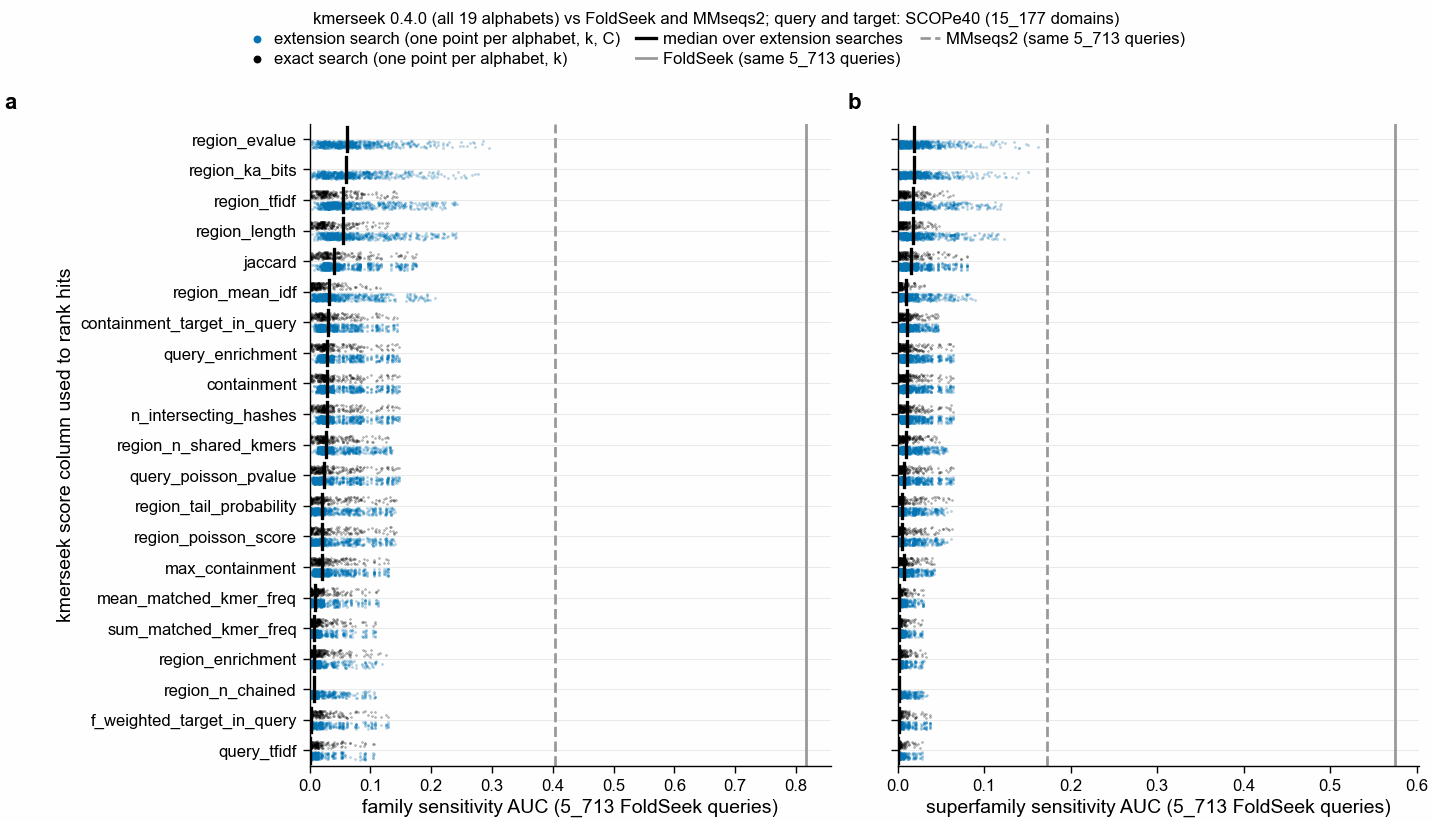

In [5]:
ok = auc.filter(pl.col("status") == "ok", pl.col("level").is_in(LEVELS)).with_columns(
    (pl.col("auc_ref_optimistic") - pl.col("auc_ref")).alias("tie_gap")
)
ext = ok.filter(pl.col("setting").is_in(EXTENSION_SETTINGS))
by_score = (
    ext.group_by("level", "score")
    .agg(
        pl.len().alias("n_searches"),
        pl.col("auc_ref").median().alias("median_auc"),
        pl.col("auc_ref").max().alias("max_auc"),
        pl.col("tie_gap").median().alias("median_tie_gap"),
        pl.col("tie_gap").max().alias("max_tie_gap"),
    )
    .sort("level", "median_auc", descending=[False, True])
)
print(
    "Extension searches only (5 settings). AUC over FoldSeek's 5_713 queries, false positive first in ties."
)
print(by_score)

order = by_score.filter(pl.col("level") == "family")["score"].to_list()
fig, axs = pf.figure(pf.TWO_COLUMN_MM, 105, ncols=2, sharey=True)
rng = np.random.default_rng(0)
for ax, level in zip(axs, LEVELS):
    sub = ok.filter(pl.col("level") == level)
    for i, sc in enumerate(order):
        for s, lab, col in [
            (
                "extension",
                "extension search (one point per alphabet, k, C)",
                pf.OKABE_ITO["blue"],
            ),
            (
                "exact",
                "exact search (one point per alphabet, k)",
                pf.OKABE_ITO["black"],
            ),
        ]:
            m = (
                pl.col("setting").is_in(EXTENSION_SETTINGS)
                if s == "extension"
                else pl.col("setting") == "exact"
            )
            v = sub.filter(pl.col("score") == sc, m)["auc_ref"].to_numpy()
            dy = 0.18 if s == "extension" else -0.18
            ax.scatter(
                v,
                i + dy + rng.uniform(-0.12, 0.12, v.size),
                s=1,
                alpha=0.3,
                color=col,
                lw=0,
                label=lab,
            )
        med = by_score.filter(pl.col("level") == level, pl.col("score") == sc)[
            "median_auc"
        ].item()
        ax.plot(
            [med, med],
            [i - 0.4, i + 0.4],
            color="black",
            lw=1.2,
            label="median over extension searches",
        )
    for tool, st in TOOL_STYLE.items():
        ax.axvline(TOOL_AUC[(tool, level)], label=f"{tool} (same 5_713 queries)", **st)
    ax.set_yticks(range(len(order)), order)
    ax.set_ylim(len(order) - 0.5, -0.5)
    for i in range(len(order)):
        ax.axhline(i, color="0.9", lw=0.3, zorder=0)
    ax.set_xlabel(f"{level} sensitivity AUC (5_713 FoldSeek queries)")
    ax.set_xlim(0, None)
axs[0].set_ylabel("kmerseek score column used to rank hits")
pf.panel_label(axs[0], "a", dx_pt=-110)
pf.panel_label(axs[1], "b")
leg = pf.shared_legend(
    fig,
    ncol=3,
    title="kmerseek 0.4.0 (all 19 alphabets) vs FoldSeek and MMseqs2; "
    "query and target: SCOPe40 (15_177 domains)",
)
for h in leg.legend_handles:
    if hasattr(h, "set_alpha"):
        h.set_alpha(1)
    if hasattr(h, "set_sizes"):
        h.set_sizes([8])
pf.save(fig, FIG_DIR / f"{FIG_STEM}_auc_by_score_column", formats=("pdf", "png"))

## 3. Best alphabet, k and setting, against FoldSeek and MMseqs2

Hits ranked by `region_evalue` (section 2's choice). `exact` searches have no E-value, so they
are ranked by `jaccard`, the column with the highest median family AUC among `exact` searches.
Each small dot is one k and setting of that alphabet. The large dot is the alphabet's best,
labelled with its k and setting; a triangle on the label means that k is the lowest k run for
that alphabet (its k_min).

exact searches ranked by: jaccard
family: best per alphabet (FoldSeek 0.817, MMseqs2 0.403)
shape: (19, 10)
┌──────────────────────────┬───────┬───────┬───────┬─────────────────┬─────────┬───────────────┬─────────┬────────────────────┬─────────────────┐
│ alphabet                 ┆ ksize ┆ k_min ┆ k_max ┆ best_k_is_k_min ┆ setting ┆ score         ┆ auc_ref ┆ auc_ref_optimistic ┆ n_ref_with_hits │
│ ---                      ┆ ---   ┆ ---   ┆ ---   ┆ ---             ┆ ---     ┆ ---           ┆ ---     ┆ ---                ┆ ---             │
│ str                      ┆ i64   ┆ i64   ┆ i64   ┆ bool            ┆ str     ┆ str           ┆ f64     ┆ f64                ┆ i64             │
╞══════════════════════════╪═══════╪═══════╪═══════╪═════════════════╪═════════╪═══════════════╪═════════╪════════════════════╪═════════════════╡
│ mmseqs12                 ┆ 6     ┆ 6     ┆ 10    ┆ true            ┆ c_max   ┆ region_evalue ┆ 0.295   ┆ 0.295              ┆ 3136            │
│ sdm12         

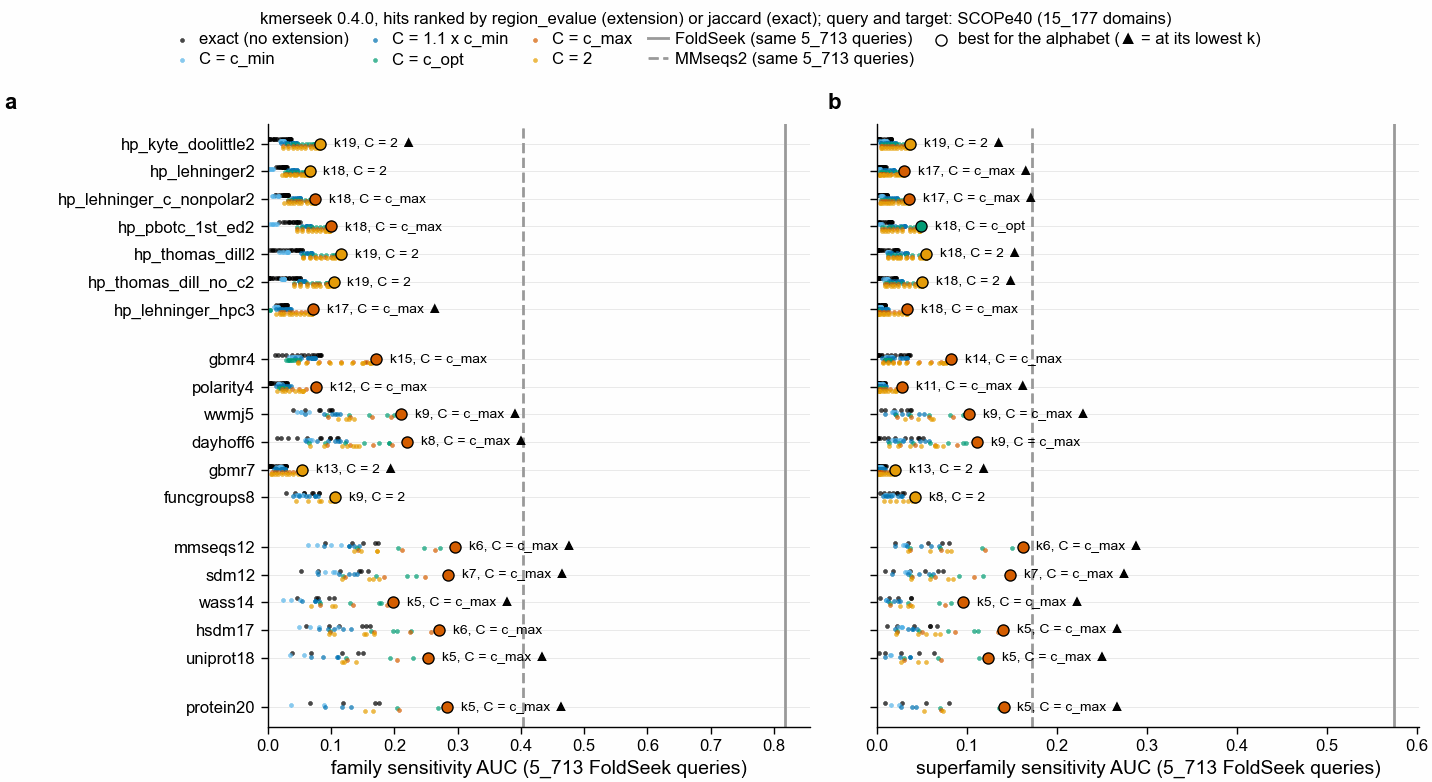

In [6]:
EXACT_SCORE = (
    ok.filter(pl.col("setting") == "exact", pl.col("level") == "family")
    .group_by("score")
    .agg(pl.col("auc_ref").median())
    .sort("auc_ref", descending=True)["score"][0]
)
print("exact searches ranked by:", EXACT_SCORE)
chosen = ok.filter(
    (pl.col("setting").is_in(EXTENSION_SETTINGS) & (pl.col("score") == "region_evalue"))
    | ((pl.col("setting") == "exact") & (pl.col("score") == EXACT_SCORE))
).join(ks, on="alphabet")
best = (
    chosen.sort("auc_ref", descending=True)
    .group_by("alphabet", "level", maintain_order=True)
    .head(1)
    .with_columns((pl.col("ksize") == pl.col("k_min")).alias("best_k_is_k_min"))
    .select(
        "level",
        "alphabet",
        "ksize",
        "k_min",
        "k_max",
        "best_k_is_k_min",
        "setting",
        "score",
        "auc_ref",
        "auc_ref_optimistic",
        "n_ref_with_hits",
    )
)
for level in LEVELS:
    print(
        f"{level}: best per alphabet (FoldSeek {TOOL_AUC[('FoldSeek', level)]:.3f}, "
        f"MMseqs2 {TOOL_AUC[('MMseqs2', level)]:.3f})"
    )
    print(
        best.filter(pl.col("level") == level)
        .sort("auc_ref", descending=True)
        .drop("level")
    )

fig, axs = pf.figure(pf.TWO_COLUMN_MM, 100, ncols=2, sharey=True)
for ax, level in zip(axs, LEVELS):
    sub = chosen.filter(pl.col("level") == level)
    for s in SETTINGS:
        ss = sub.filter(pl.col("setting") == s)
        ax.scatter(
            ss["auc_ref"],
            [pos[a] + 0.15 * (SETTINGS.index(s) - 2.5) / 2.5 for a in ss["alphabet"]],
            s=3,
            color=SETTING_COLOUR[s],
            lw=0,
            alpha=0.7,
            label=SETTING_LABEL[s],
        )
    for r in best.filter(pl.col("level") == level).iter_rows(named=True):
        ax.scatter(
            r["auc_ref"],
            pos[r["alphabet"]],
            s=16,
            color=SETTING_COLOUR[r["setting"]],
            edgecolor="black",
            lw=0.5,
            zorder=3,
        )
        tag = " ▲" if r["best_k_is_k_min"] else ""
        ax.annotate(
            f"k{r['ksize']}, {SETTING_LABEL[r['setting']]}{tag}",
            (r["auc_ref"], pos[r["alphabet"]]),
            xytext=(5, 0),
            textcoords="offset points",
            va="center",
            fontsize=5,
        )
    for tool, st in TOOL_STYLE.items():
        ax.axvline(TOOL_AUC[(tool, level)], label=f"{tool} (same 5_713 queries)", **st)
    alphabet_axis(ax, pos)
    ax.set_xlim(0, TOOL_AUC[("FoldSeek", level)] * 1.05)
    ax.set_xlabel(f"{level} sensitivity AUC (5_713 FoldSeek queries)")
axs[0].scatter(
    [],
    [],
    s=16,
    color="white",
    edgecolor="black",
    lw=0.5,
    label="best for the alphabet (▲ = at its lowest k)",
)
pf.panel_label(axs[0], "a", dx_pt=-95)
pf.panel_label(axs[1], "b")
pf.shared_legend(
    fig,
    ncol=5,
    title="kmerseek 0.4.0, hits ranked by region_evalue (extension) or jaccard (exact); "
    "query and target: SCOPe40 (15_177 domains)",
)
pf.save(fig, FIG_DIR / f"{FIG_STEM}_best_per_alphabet", formats=("pdf", "png"))

## 4. Sensitivity against k for the HP alphabets and protein20

The same ranking as section 3, family level, every k run. x is k (numeric), one line per
setting. A grey cross on the x axis marks a k where kmerseek refused that setting (no E-value
fit). Under each HP alphabet's name are its residue classes as kmerseek defines them: H
(hydrophobic), P (polar), and for `hp_lehninger_hpc3` a third class, C, for cysteine alone.

{'hp_kyte_doolittle2': {'H': 'ACFILMV', 'P': 'DEGHKNPQRSTWY'}, 'hp_lehninger2': {'H': 'AFGILMPVWY', 'P': 'CDEHKNQRST'}, 'hp_lehninger_c_nonpolar2': {'H': 'ACFGILMPVWY', 'P': 'DEHKNQRST'}, 'hp_pbotc_1st_ed2': {'H': 'ACFILMPVWY', 'P': 'DEGHKNQRST'}, 'hp_thomas_dill2': {'H': 'ACFILMVWY', 'P': 'DEGHKNPQRST'}, 'hp_thomas_dill_no_c2': {'H': 'AFILMVWY', 'P': 'CDEGHKNPQRST'}, 'hp_lehninger_hpc3': {'H': 'AFGILMPVWY', 'P': 'DEHKNQRST', 'C': 'C'}}
Family AUC by k (columns: setting), HP alphabets and protein20
hp_kyte_doolittle2
shape: (21, 7)
┌───────┬───────┬───────┬────────────┬───────┬───────┬───────┐
│ ksize ┆ exact ┆ c_min ┆ c_min_x1.1 ┆ c_opt ┆ c_max ┆ c2    │
│ ---   ┆ ---   ┆ ---   ┆ ---        ┆ ---   ┆ ---   ┆ ---   │
│ i64   ┆ f64   ┆ f64   ┆ f64        ┆ f64   ┆ f64   ┆ f64   │
╞═══════╪═══════╪═══════╪════════════╪═══════╪═══════╪═══════╡
│ 19    ┆ 0.024 ┆ 0.019 ┆ 0.040      ┆ 0.073 ┆ 0.078 ┆ 0.082 │
│ 20    ┆ 0.028 ┆ 0.023 ┆ 0.044      ┆ 0.073 ┆ 0.077 ┆ 0.081 │
│ 21    ┆ 0.031 ┆ 0.0

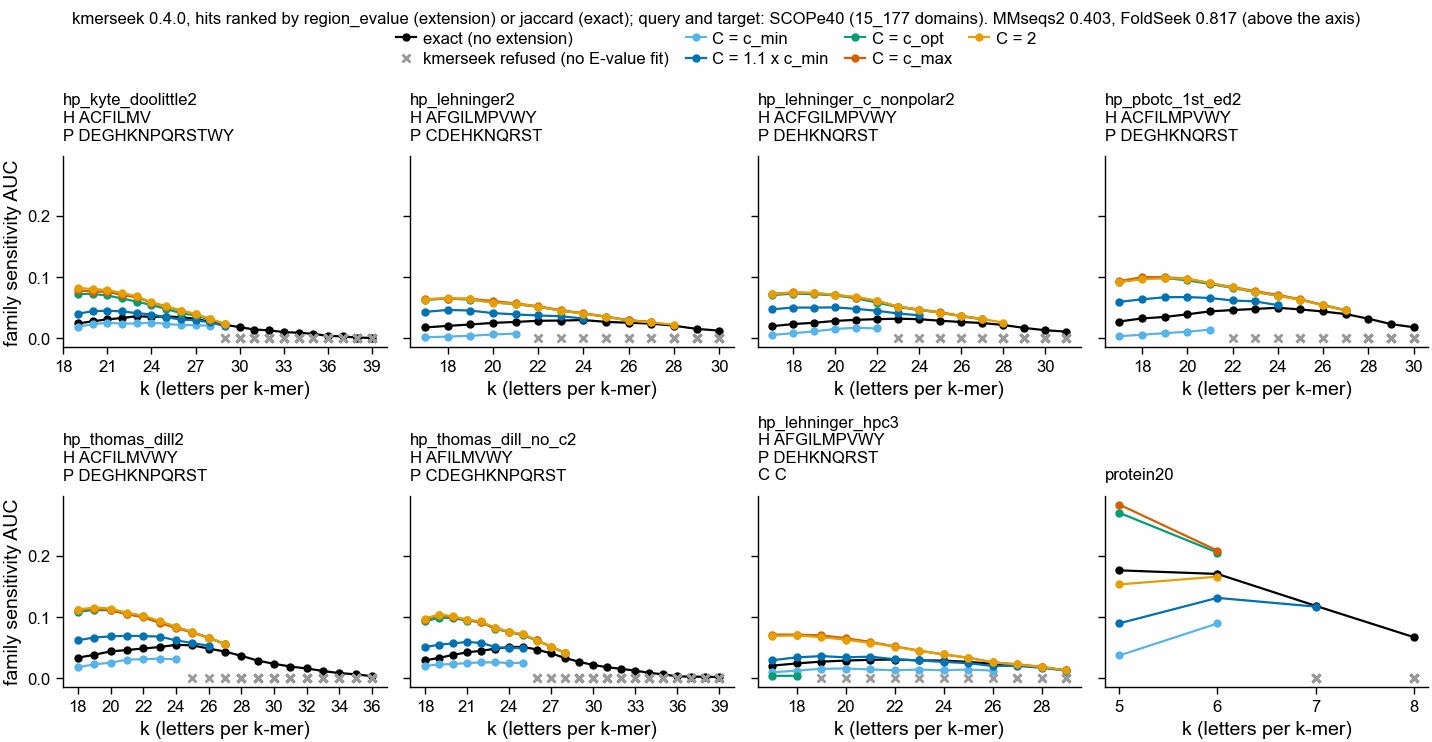

In [7]:
import ortholog_analysis_utils as ou

PANELS = [a for a in ALPHABETS if a.startswith("hp_")] + ["protein20"]
# Residue classes as kmerseek defines them (src/rust/alphabets.rs, kmerseek d79f863);
# ortholog_analysis_utils holds the two-class ones under names without the trailing 2.
OU_NAME = {"hp_lehninger_c_nonpolar2": "hp_lehninger_plus_c"}
HP_CLASSES = {}
for a in PANELS[:-1]:
    g = ou.ALPHABET_AA_GROUPS.get(OU_NAME.get(a, re.sub(r"2$", "", a)))
    if g:
        HP_CLASSES[a] = {k.upper(): v for k, v in g.items()}
HP_CLASSES["hp_lehninger_hpc3"] = {"H": "AFGILMPVWY", "P": "DEHKNQRST", "C": "C"}
print(HP_CLASSES)
nofit = (
    auc.filter(pl.col("status") == "nofit")
    .select("alphabet", "ksize", "setting")
    .unique()
)
fam = chosen.filter(pl.col("level") == "family")
print("Family AUC by k (columns: setting), HP alphabets and protein20")
for a in PANELS:
    print(a)
    print(
        fam.filter(pl.col("alphabet") == a)
        .pivot(on="setting", index="ksize", values="auc_ref")
        .sort("ksize")
        .select(
            ["ksize"]
            + [
                s
                for s in SETTINGS
                if s in fam.filter(pl.col("alphabet") == a)["setting"].unique()
            ]
        )
    )

fig, axs = pf.figure(pf.TWO_COLUMN_MM, 95, nrows=2, ncols=4, sharey=True)
for ax, a in zip(axs.flat, PANELS):
    sub = fam.filter(pl.col("alphabet") == a)
    for s in SETTINGS:
        ss = sub.filter(pl.col("setting") == s).sort("ksize")
        ax.plot(
            ss["ksize"],
            ss["auc_ref"],
            marker="o",
            ms=2,
            lw=0.8,
            color=SETTING_COLOUR[s],
            label=SETTING_LABEL[s],
        )
        nf = nofit.filter(pl.col("alphabet") == a, pl.col("setting") == s)["ksize"]
        ax.plot(
            nf,
            np.zeros(len(nf)),
            ls="",
            marker="x",
            ms=3,
            color=pf.GREY,
            label="kmerseek refused (no E-value fit)",
        )
    classes = HP_CLASSES.get(a, {})
    ax.set_title(
        "\n".join([a] + [f"{c} {aas}" for c, aas in classes.items()]),
        fontsize=6,
        loc="left",
    )
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax.set_xlabel("k (letters per k-mer)")
axs[0, 0].set_ylabel("family sensitivity AUC")
axs[1, 0].set_ylabel("family sensitivity AUC")
pf.shared_legend(
    fig,
    ncol=4,
    title="kmerseek 0.4.0, hits ranked by region_evalue (extension) or jaccard (exact); "
    "query and target: SCOPe40 (15_177 domains). "
    f"MMseqs2 {TOOL_AUC[('MMseqs2', 'family')]:.3f}, FoldSeek {TOOL_AUC[('FoldSeek', 'family')]:.3f} (above the axis)",
)
pf.save(fig, FIG_DIR / f"{FIG_STEM}_hp_protein20_auc_vs_k", formats=("pdf", "png"))

## 5. Does extension beat exact matching?

One point per alphabet-ksize pair and extension setting: x is the family AUC of the `exact`
search (ranked by `jaccard`), y the same pair's AUC with extension (ranked by `region_evalue`).
Above the grey diagonal, extension found more true positives before the first false positive.

Family AUC, extension vs exact, per alphabet-ksize pair where the extension search returned hits
shape: (5, 5)
┌────────────┬─────────┬────────────────────┬──────────────┬──────────────────┐
│ setting    ┆ n_pairs ┆ n_extension_better ┆ median_exact ┆ median_extension │
│ ---        ┆ ---     ┆ ---                ┆ ---          ┆ ---              │
│ str        ┆ i64     ┆ i64                ┆ f64          ┆ f64              │
╞════════════╪═════════╪════════════════════╪══════════════╪══════════════════╡
│ c_min      ┆ 110     ┆ 0                  ┆ 0.041        ┆ 0.025            │
│ c_min_x1.1 ┆ 141     ┆ 71                 ┆ 0.044        ┆ 0.055            │
│ c_opt      ┆ 117     ┆ 99                 ┆ 0.044        ┆ 0.072            │
│ c_max      ┆ 140     ┆ 140                ┆ 0.036        ┆ 0.074            │
│ c2         ┆ 151     ┆ 142                ┆ 0.036        ┆ 0.070            │
└────────────┴─────────┴────────────────────┴──────────────┴──────────────────┘


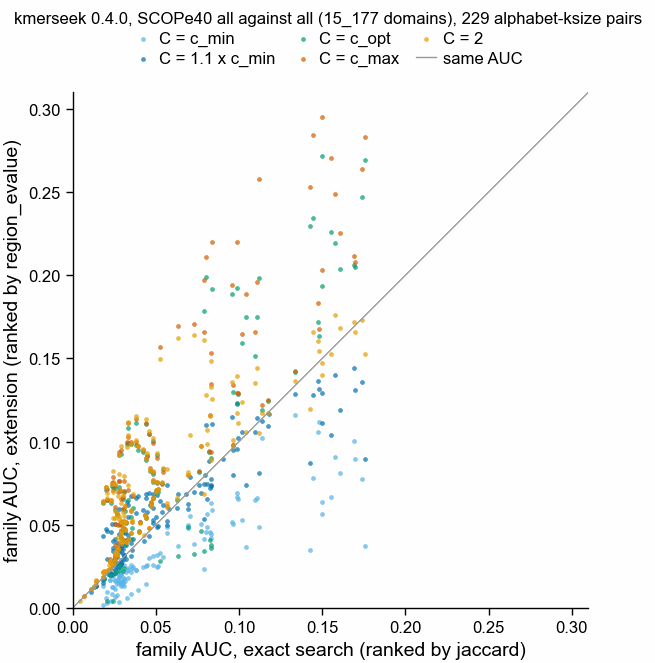

In [8]:
fam_w = fam.pivot(on="setting", index=["alphabet", "ksize"], values="auc_ref")
rows = []
for s in EXTENSION_SETTINGS:
    sub = fam_w.select(
        "alphabet", "ksize", "exact", pl.col(s).alias("ext")
    ).drop_nulls()
    rows.append(
        {
            "setting": s,
            "n_pairs": sub.height,
            "n_extension_better": int((sub["ext"] > sub["exact"]).sum()),
            "median_exact": sub["exact"].median(),
            "median_extension": sub["ext"].median(),
        }
    )
vs_exact = pl.DataFrame(rows)
print(
    "Family AUC, extension vs exact, per alphabet-ksize pair where the extension search returned hits"
)
print(vs_exact)

fig, ax = pf.figure(pf.ONE_COLUMN_MM, 85)
for s in EXTENSION_SETTINGS:
    sub = fam_w.select("exact", s).drop_nulls()
    ax.scatter(
        sub["exact"],
        sub[s],
        s=3,
        lw=0,
        alpha=0.7,
        color=SETTING_COLOUR[s],
        label=SETTING_LABEL[s],
    )
lim = max(fam_w.select(pl.exclude("alphabet", "ksize")).max().row(0)) * 1.05
ax.plot([0, lim], [0, lim], color=pf.GREY, lw=0.5, label="same AUC")
ax.set_xlim(0, lim)
ax.set_ylim(0, lim)
ax.set_aspect("equal")
ax.set_xlabel("family AUC, exact search (ranked by jaccard)")
ax.set_ylabel("family AUC, extension (ranked by region_evalue)")
fig.legend(
    loc="outside upper center",
    ncol=3,
    title="kmerseek 0.4.0, SCOPe40 all against all (15_177 domains), 229 alphabet-ksize pairs",
)
pf.save(fig, FIG_DIR / f"{FIG_STEM}_extension_vs_exact", formats=("pdf", "png"))

## 6. Below k_min, on two scales

Section 3 left one question open: for 10 of 19 alphabets the best k was the lowest k run, so
sensitivity might keep rising at smaller k. The follow-up run
([PR 107](https://github.com/seanome/2024-kmerseek-analysis/pull/107), step 3, head job
47646307, 2026-10-13, same image and settings) searched every alphabet-ksize pair of the first
sweep again plus k_min − 1 and k_min − 2 for the 16 alphabets whose best family or superfamily
AUC sat at k_min, never under 15 bits per k-mer (k × log2 classes): 1_520 searches, all
scored. funcgroups8, gbmr4 and hp_pbotc_1st_ed2 were left out of the lower k-sizes: their best
k was above k_min. This run also scores the class level and the database scale below, so
sections 6-8 read it.

**Two scales.** Sections 2-5 divide each query's count by the true positives kmerseek
*reported* for that query (as `eval_tsv_to_rocx` does). FoldSeek's and MMseqs2's `.rocx` files
divide by every true positive in the database: for all 5_713 queries, sensitivity × (family
size − 1) is a whole number. A query where kmerseek reports 2 of its 24 family members, both
above the first false positive, scores 1.0 on the first scale and 2/24 on the second. Only
the database scale (`auc_ref_db`) compares with the two tools. A smaller k reports more pairs,
so it can lose on the first scale and win on the second.

The rule was set before the run: if the best AUC below k_min beats the best at k_min to k_max
for most alphabets, the best k moves down; otherwise section 3's best k-sizes stand.

The figure puts the two k ranges on one row per alphabet: a circle at the best AUC at k_min to
k_max, a triangle at the best AUC below k_min, each labelled with its k. Top row: the
reported-hits scale; bottom row: the database scale. A triangle to the right of its circle
means the smaller k-sizes did better. Hits are ranked as in section 3.

/Users/olga/data/scope/results-scope40-alphabet-ksize-v040-full-identity/scope40_v040_auc.tsv sha256 076d0cc81b55acd712bbe98fd6399b9553d41eef8b5c80151c8ebc1636969095
/Users/olga/data/scope/results-scope40-alphabet-ksize-v040-full-identity/scope40_v040_identity_bands.tsv sha256 925702867f6f209700d123daf34674dc87ce6d016f1f04d237e34725c8f7afe3


1520 searches
shape: (3, 2)
┌──────────┬───────┐
│ status   ┆ len   │
│ ---      ┆ ---   │
│ str      ┆ u32   │
╞══════════╪═══════╡
│ constant ┆ 784   │
│ nofit    ┆ 472   │
│ ok       ┆ 84896 │
└──────────┴───────┘
First sweep against its rerun, largest AUC difference per score column (columns that differ):
shape: (4, 3)
┌────────────────────────┬──────────┬─────────────────────────────────┐
│ score                  ┆ diff     ┆ searches_with_other_pair_count… │
│ ---                    ┆ ---      ┆ ---                             │
│ str                    ┆ f64      ┆ u32                             │
╞════════════════════════╪══════════╪═════════════════════════════════╡
│ mean_matched_kmer_freq ┆ 0.000263 ┆ 0                               │
│ sum_matched_kmer_freq  ┆ 0.000263 ┆ 0                               │
│ region_evalue          ┆ 0.000088 ┆ 0                               │
│ region_ka_bits         ┆ 0.000088 ┆ 0                               │
└────────────────────────┴─

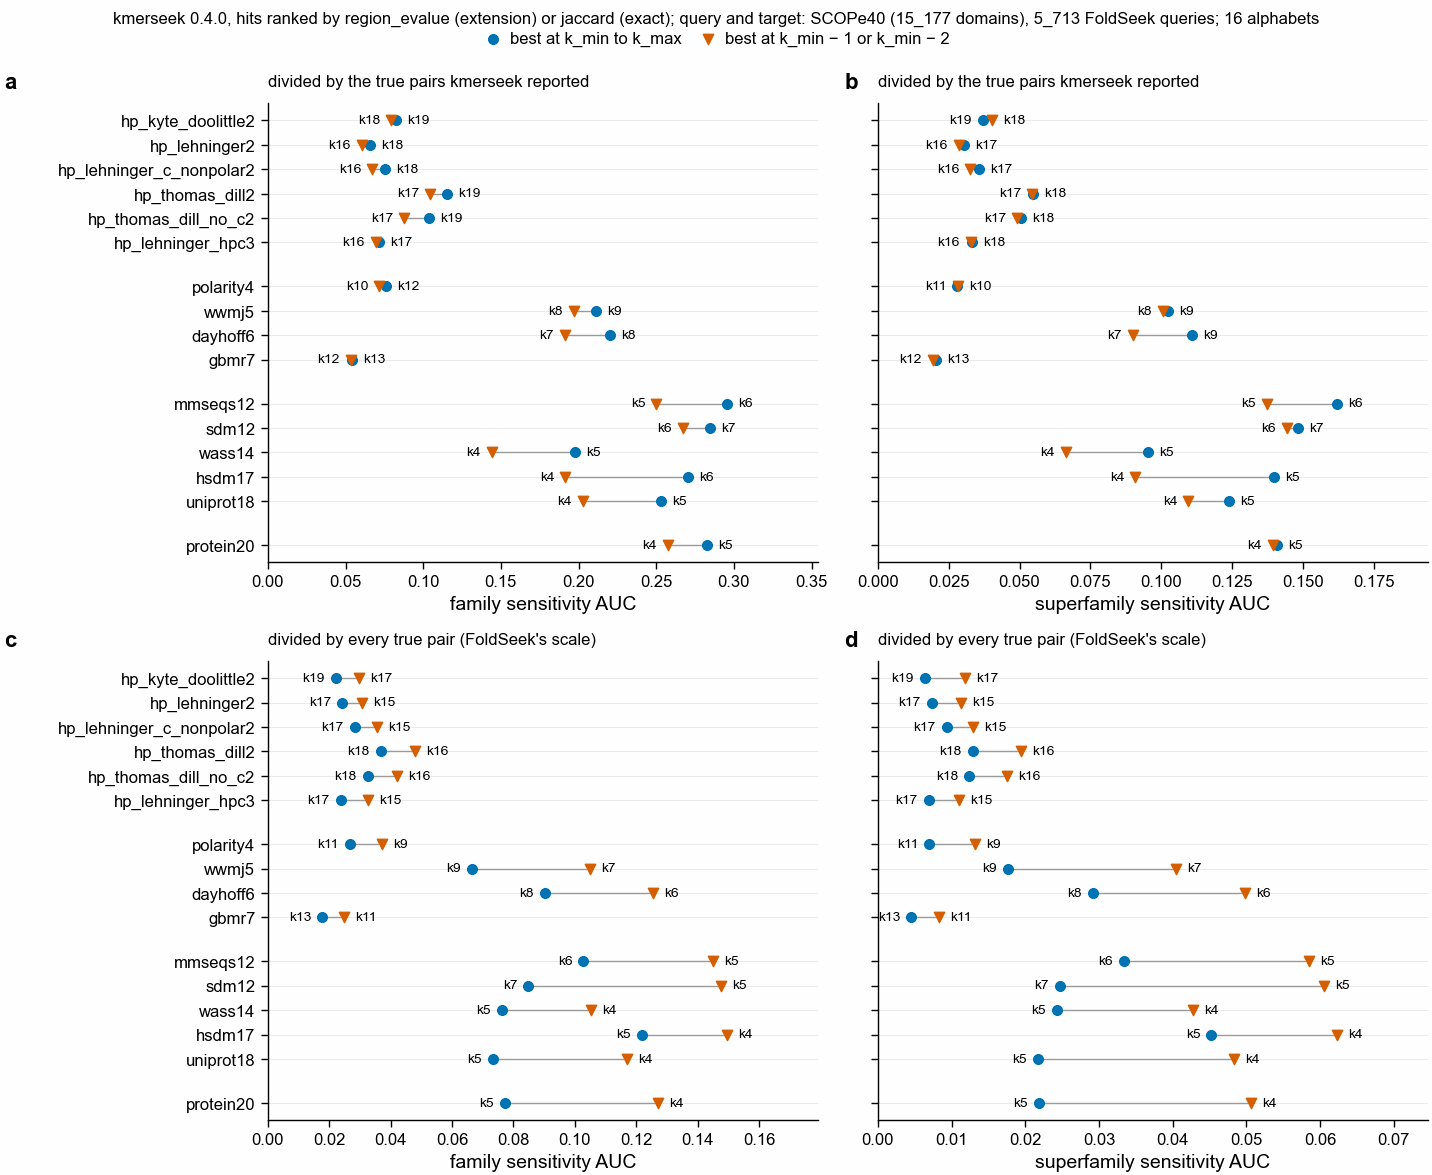

In [9]:
FULL_DIR = Path(
    os.environ.get(
        "NB277_FULL_DIR",
        Path.home() / "data/scope/results-scope40-alphabet-ksize-v040-full-identity",
    )
)
full_tables = {}
for name in ("scope40_v040_auc.tsv", "scope40_v040_identity_bands.tsv"):
    path = FULL_DIR / name
    print(path, "sha256", hashlib.sha256(path.read_bytes()).hexdigest())
    full_tables[name] = pl.read_csv(path, separator="\t", infer_schema_length=None)
full = full_tables["scope40_v040_auc.tsv"]
print(full.select("alphabet", "ksize", "setting").unique().height, "searches")
print(full.group_by("status").len().sort("status"))

# The reruns of the first sweep's searches report the same pairs (same n_pairs); the AUCs of the
# two columns ranked by here (region_evalue, jaccard) agree to within 0.0001. The k-mer
# frequency columns differ in their last digits between runs, which moves some ties.
KEY = ["alphabet", "ksize", "setting", "score", "level"]
rerun = (
    auc.filter(pl.col("status") == "ok")
    .select(KEY + ["auc_ref", "n_pairs"])
    .join(
        full.filter(pl.col("status") == "ok").select(
            KEY
            + [
                pl.col("auc_ref").alias("auc_ref_rerun"),
                pl.col("n_pairs").alias("n_pairs_rerun"),
            ]
        ),
        on=KEY,
    )
)
print(
    "First sweep against its rerun, largest AUC difference per score column (columns that differ):"
)
with pl.Config(float_precision=6):
    print(
        rerun.with_columns(
            (pl.col("auc_ref") - pl.col("auc_ref_rerun")).abs().alias("diff")
        )
        .group_by("score")
        .agg(
            pl.col("diff").max(),
            (pl.col("n_pairs") != pl.col("n_pairs_rerun"))
            .sum()
            .alias("searches_with_other_pair_counts"),
        )
        .filter(pl.col("diff") > 0)
        .sort("diff", descending=True)
    )

ranked_full = (
    full.filter(pl.col("status") == "ok")
    .filter(
        (
            pl.col("setting").is_in(EXTENSION_SETTINGS)
            & (pl.col("score") == "region_evalue")
        )
        | ((pl.col("setting") == "exact") & (pl.col("score") == EXACT_SCORE))
    )
    .join(ks.select("alphabet", "k_min"), on="alphabet")
)
below_alphabets = sorted(
    set(ranked_full.filter(pl.col("ksize") < pl.col("k_min"))["alphabet"])
)


def best_in_range(d, metric, tag):
    "Best AUC per alphabet and level on one scale."
    return (
        d.sort(metric, descending=True)
        .group_by("alphabet", "level")
        .head(1)
        .select(
            "alphabet",
            "level",
            pl.col("ksize").alias(f"k_{tag}"),
            pl.col("setting").alias(f"setting_{tag}"),
            pl.col(metric).alias(f"auc_{tag}"),
        )
    )


compare = {}
for metric in ("auc_ref", "auc_ref_db"):
    d = ranked_full.filter(
        pl.col("alphabet").is_in(below_alphabets),
        pl.col("level").is_in(["family", "superfamily", "fold"]),
    )
    compare[metric] = (
        best_in_range(d.filter(pl.col("ksize") < pl.col("k_min")), metric, "below")
        .join(
            best_in_range(
                d.filter(pl.col("ksize") >= pl.col("k_min")), metric, "first"
            ),
            on=["alphabet", "level"],
        )
        .with_columns((pl.col("auc_below") - pl.col("auc_first")).alias("change"))
        .sort("level", "alphabet")
    )
    print(
        f"{metric}: how many of the {len(below_alphabets)} alphabets do better below k_min"
    )
    print(
        compare[metric]
        .group_by("level")
        .agg(
            (pl.col("change") > 0).sum().alias("n_better_below_kmin"),
            pl.len().alias("n_alphabets"),
            pl.col("change").max().alias("largest_change"),
        )
        .sort("level")
    )
print("Best AUC per alphabet on the database scale, k_min to k_max and below k_min")
with pl.Config(float_precision=4):
    print(
        compare["auc_ref_db"]
        .filter(pl.col("level") != "fold")
        .sort("level", "auc_below", descending=[False, True])
    )

BELOW_COLOUR = {"first": pf.OKABE_ITO["blue"], "below": pf.OKABE_ITO["vermillion"]}
bpos = alphabet_positions([a for a in ALPHABETS if a in below_alphabets])
SCALE_LABEL = {
    "auc_ref": "divided by the true pairs kmerseek reported",
    "auc_ref_db": "divided by every true pair (FoldSeek's scale)",
}
fig, axs = pf.figure(pf.TWO_COLUMN_MM, 150, nrows=2, ncols=2, sharey=True)
for row, metric in enumerate(("auc_ref", "auc_ref_db")):
    for col, level in enumerate(LEVELS):
        ax = axs[row, col]
        sub = compare[metric].filter(pl.col("level") == level)
        for r in sub.iter_rows(named=True):
            y = bpos[r["alphabet"]]
            ax.plot(
                [r["auc_below"], r["auc_first"]],
                [y, y],
                color=pf.GREY,
                lw=0.5,
                zorder=1,
            )
            left_first = r["auc_first"] < r["auc_below"]
            ax.annotate(
                f"k{r['k_first']}",
                (r["auc_first"], y),
                xytext=(-4 if left_first else 4, 0),
                textcoords="offset points",
                va="center",
                ha="right" if left_first else "left",
                fontsize=5,
            )
            ax.annotate(
                f"k{r['k_below']}",
                (r["auc_below"], y),
                xytext=(4 if left_first else -4, 0),
                textcoords="offset points",
                va="center",
                ha="left" if left_first else "right",
                fontsize=5,
            )
        ax.scatter(
            sub["auc_first"],
            [bpos[a] for a in sub["alphabet"]],
            s=12,
            marker="o",
            color=BELOW_COLOUR["first"],
            zorder=2,
            label="best at k_min to k_max",
        )
        ax.scatter(
            sub["auc_below"],
            [bpos[a] for a in sub["alphabet"]],
            s=14,
            marker="v",
            color=BELOW_COLOUR["below"],
            zorder=3,
            label="best at k_min − 1 or k_min − 2",
        )
        alphabet_axis(ax, bpos)
        ax.set_xlim(
            0,
            sub.select(pl.max_horizontal("auc_first", "auc_below")).max().item() * 1.2,
        )
        ax.set_xlabel(f"{level} sensitivity AUC")
        ax.set_title(SCALE_LABEL[metric], fontsize=6, loc="left")
for ax, letter in zip(axs.flat, "abcd"):
    pf.panel_label(ax, letter, dx_pt=-95 if letter in "ac" else -12)
pf.shared_legend(
    fig,
    ncol=2,
    title="kmerseek 0.4.0, hits ranked by region_evalue (extension) or jaccard (exact); "
    "query and target: SCOPe40 (15_177 domains), 5_713 FoldSeek queries; 16 alphabets",
)
pf.save(fig, FIG_DIR / f"{FIG_STEM}_below_kmin", formats=("pdf", "png"))

## 7. Same scale as FoldSeek and MMseqs2, fold and class levels, and identity bands

**Data.** The 1_520 searches of section 6 (step 3, head job 47646307, 2026-10-13): every
alphabet at k_min to k_max and, for 16 alphabets, k_min − 1 and k_min − 2. Query set and target
database are the 15_177 SCOPe40 domains, as before. Every number is on the database scale
(`auc_ref_db`, section 6), the scale FoldSeek's and MMseqs2's files use.

**Two more levels.** Fold: true positive = same fold, different superfamily (as in section
3). Class: true positive = same SCOP class, different fold; false positive = a different
class. Neither tool's file has a class level.

**Identity bands.** Notebook 230's USalign pairs of SCOPe40 domains, each scored in both
directions, split by the share of identical residues over the structure-aligned columns. A
pair counts when kmerseek ranks it above the query's first false positive: the first
different-fold hit, or for class pairs the first different-class hit. A tie counts against
kmerseek.

Decision: if any HP alphabet beats protein20 and the 12-letter alphabets in the under-20%
band at some level, that level is where SCOPe40 can support the HP case; otherwise SCOPe40
stays a protein20 result (section 3).

Best AUC per alphabet on FoldSeek's scale (auc_ref_db) and on the reported-hits scale (auc_ref)
shape: (19, 5)
┌──────────────────────────┬─────────┬─────────────┬─────────┬─────────┐
│ alphabet                 ┆ family  ┆ superfamily ┆ fold    ┆ class   │
│ ---                      ┆ ---     ┆ ---         ┆ ---     ┆ ---     │
│ str                      ┆ f64     ┆ f64         ┆ f64     ┆ f64     │
╞══════════════════════════╪═════════╪═════════════╪═════════╪═════════╡
│ hsdm17                   ┆ 0.14945 ┆ 0.06222     ┆ 0.00020 ┆ 0.00024 │
│ sdm12                    ┆ 0.14760 ┆ 0.06047     ┆ 0.00016 ┆ 0.00019 │
│ mmseqs12                 ┆ 0.14511 ┆ 0.05855     ┆ 0.00018 ┆ 0.00012 │
│ protein20                ┆ 0.12715 ┆ 0.05068     ┆ 0.00017 ┆ 0.00012 │
│ dayhoff6                 ┆ 0.12543 ┆ 0.04984     ┆ 0.00021 ┆ 0.00022 │
│ uniprot18                ┆ 0.11715 ┆ 0.04836     ┆ 0.00015 ┆ 0.00013 │
│ wass14                   ┆ 0.10531 ┆ 0.04280     ┆ 0.00028 ┆ 0.00017 │
│ wwmj5      

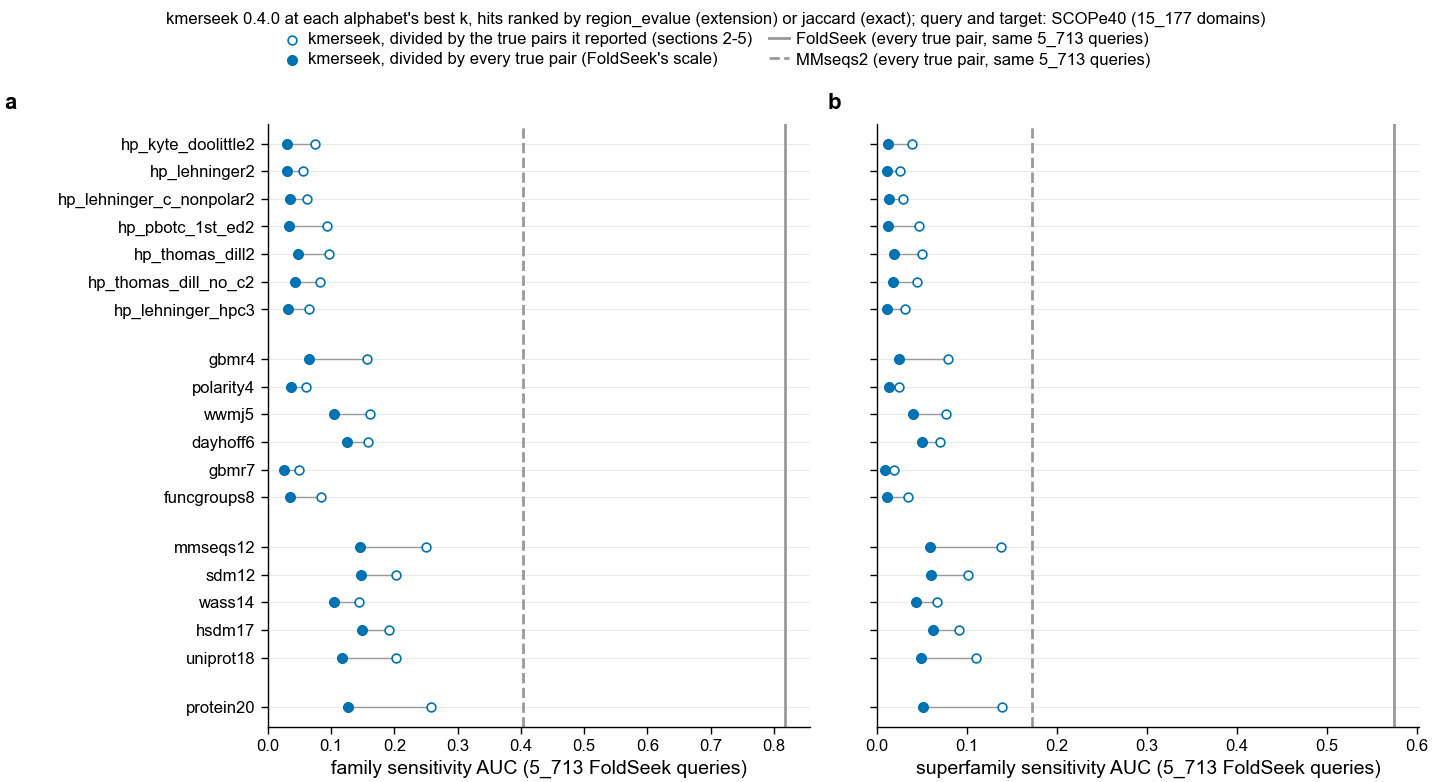

In [10]:
s2 = full
ALL_LEVELS = ["family", "superfamily", "fold", "class"]
ranked2 = s2.filter(pl.col("status") == "ok").filter(
    (pl.col("setting").is_in(EXTENSION_SETTINGS) & (pl.col("score") == "region_evalue"))
    | ((pl.col("setting") == "exact") & (pl.col("score") == EXACT_SCORE))
)
best_db = (
    ranked2.sort("auc_ref_db", descending=True)
    .group_by("alphabet", "level")
    .head(1)
    .select("alphabet", "level", "ksize", "setting", "auc_ref_db", "auc_ref")
)
print(
    "Best AUC per alphabet on FoldSeek's scale (auc_ref_db) and on the reported-hits scale (auc_ref)"
)
with pl.Config(float_precision=5):
    print(
        best_db.pivot(on="level", index="alphabet", values="auc_ref_db")
        .select(["alphabet"] + ALL_LEVELS)
        .sort("family", descending=True)
    )
for level in ["family", "superfamily", "fold"]:
    top = (
        best_db.filter(pl.col("level") == level)
        .sort("auc_ref_db", descending=True)
        .row(0, named=True)
    )
    print(
        f"{level}: best kmerseek {top['alphabet']} k{top['ksize']} {top['setting']} {top['auc_ref_db']:.4f} "
        f"(reported-hits scale {top['auc_ref']:.4f}); MMseqs2 {TOOL_AUC[('MMseqs2', level)]:.4f}, "
        f"FoldSeek {TOOL_AUC[('FoldSeek', level)]:.4f}"
    )

fig, axs = pf.figure(pf.TWO_COLUMN_MM, 100, ncols=2, sharey=True)
for ax, level in zip(axs, LEVELS):
    sub = best_db.filter(pl.col("level") == level)
    ax.scatter(
        sub["auc_ref"],
        [pos[a] for a in sub["alphabet"]],
        s=10,
        marker="o",
        facecolor="white",
        edgecolor=pf.OKABE_ITO["blue"],
        lw=0.6,
        zorder=2,
        label="kmerseek, divided by the true pairs it reported (sections 2-5)",
    )
    ax.scatter(
        sub["auc_ref_db"],
        [pos[a] for a in sub["alphabet"]],
        s=12,
        marker="o",
        color=pf.OKABE_ITO["blue"],
        zorder=3,
        label="kmerseek, divided by every true pair (FoldSeek's scale)",
    )
    for r in sub.iter_rows(named=True):
        ax.plot(
            [r["auc_ref_db"], r["auc_ref"]],
            [pos[r["alphabet"]]] * 2,
            color=pf.GREY,
            lw=0.5,
            zorder=1,
        )
    for tool, st in TOOL_STYLE.items():
        ax.axvline(
            TOOL_AUC[(tool, level)],
            label=f"{tool} (every true pair, same 5_713 queries)",
            **st,
        )
    alphabet_axis(ax, pos)
    ax.set_xlim(0, TOOL_AUC[("FoldSeek", level)] * 1.05)
    ax.set_xlabel(f"{level} sensitivity AUC (5_713 FoldSeek queries)")
pf.panel_label(axs[0], "a", dx_pt=-95)
pf.panel_label(axs[1], "b")
pf.shared_legend(
    fig,
    ncol=2,
    title="kmerseek 0.4.0 at each alphabet's best k, hits ranked by region_evalue (extension) "
    "or jaccard (exact); query and target: SCOPe40 (15_177 domains)",
)
pf.save(fig, FIG_DIR / f"{FIG_STEM}_same_scale_as_foldseek", formats=("pdf", "png"))

The next figure shows, for pairs under 20% identity, the share each alphabet ranks above the
query's first false positive, at its best k and setting for that pair class. One panel per
pair class; the x axis of each panel is fitted to its own values. The table under it gives the
counts behind each share, and the same share at every identity band.

Under 20% identity: pairs, reported, ranked above the first false positive (best k and setting per alphabet)
shape: (76, 8)
┌──────────────────────────────┬──────────────────────────┬───────┬────────────┬─────────┬────────────┬──────────────────┬──────────────────────┐
│ category                     ┆ alphabet                 ┆ ksize ┆ setting    ┆ n_pairs ┆ n_reported ┆ n_above_first_fp ┆ share_above_first_fp │
│ ---                          ┆ ---                      ┆ ---   ┆ ---        ┆ ---     ┆ ---        ┆ ---              ┆ ---                  │
│ str                          ┆ str                      ┆ i64   ┆ str        ┆ i64     ┆ i64        ┆ i64              ┆ f64                  │
╞══════════════════════════════╪══════════════════════════╪═══════╪════════════╪═════════╪════════════╪══════════════════╪══════════════════════╡
│ diff_fold_same_class         ┆ polarity4                ┆ 11    ┆ exact      ┆ 15946   ┆ 988        ┆ 83               ┆ 0.00521              │


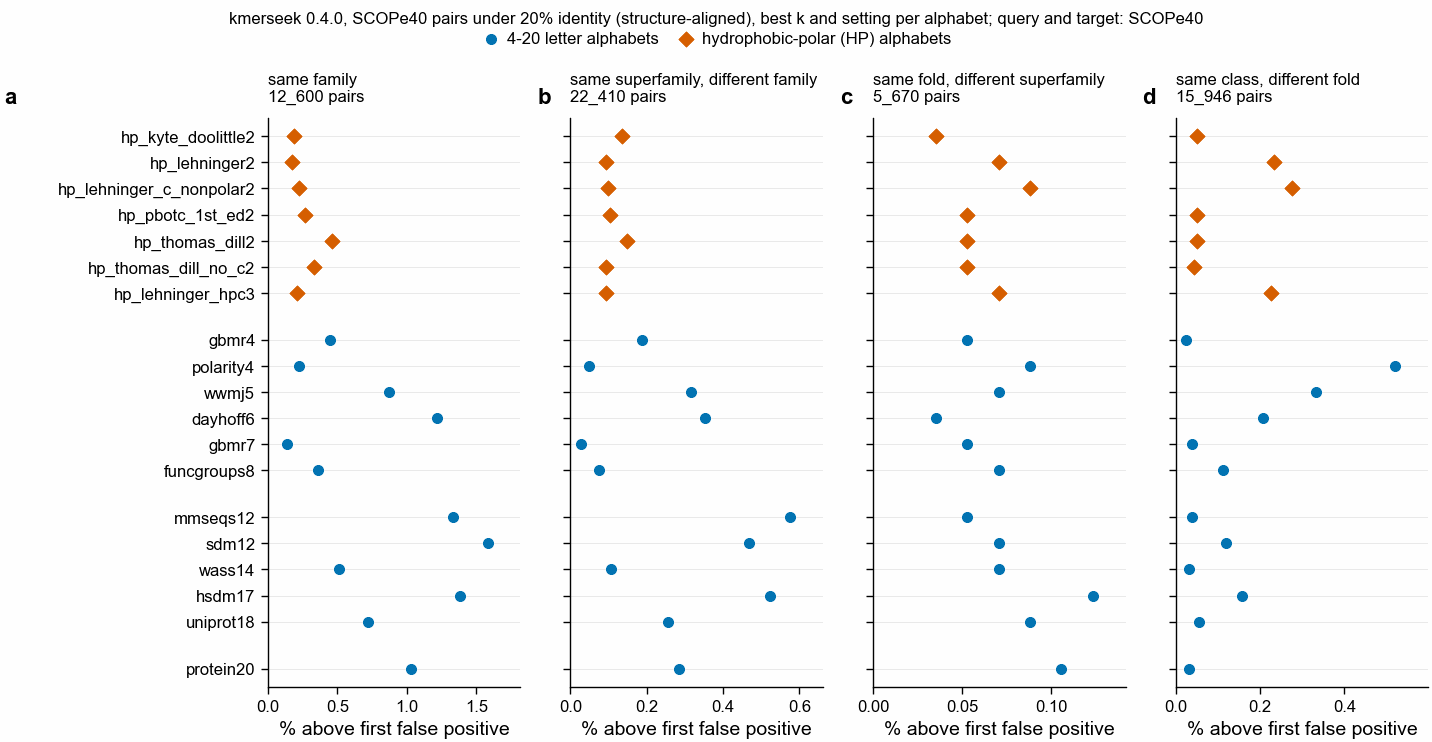

In [11]:
bands2 = (
    full_tables["scope40_v040_identity_bands.tsv"]
    .filter(pl.col("status") == "ok")
    .filter(
        (
            pl.col("setting").is_in(EXTENSION_SETTINGS)
            & (pl.col("score") == "region_evalue")
        )
        | ((pl.col("setting") == "exact") & (pl.col("score") == EXACT_SCORE))
    )
    .with_columns(
        (pl.col("n_above_first_fp") / pl.col("n_pairs")).alias("share_above_first_fp")
    )
)
best_band = (
    bands2.sort("share_above_first_fp", descending=True)
    .group_by("alphabet", "category", "identity_band")
    .head(1)
)
CATEGORY_LABEL = {
    "same_family": "same family",
    "same_superfamily_diff_family": "same superfamily, different family",
    "same_fold_diff_superfamily": "same fold, different superfamily",
    "diff_fold_same_class": "same class, different fold",
}
under20 = best_band.filter(pl.col("identity_band") == "0-20%")
print(
    "Under 20% identity: pairs, reported, ranked above the first false positive (best k and setting per alphabet)"
)
with pl.Config(float_precision=5):
    print(
        under20.select(
            "category",
            "alphabet",
            "ksize",
            "setting",
            "n_pairs",
            "n_reported",
            "n_above_first_fp",
            "share_above_first_fp",
        ).sort("category", "share_above_first_fp", descending=[False, True])
    )
print("Best share over all alphabets, by pair class and identity band")
print(
    best_band.group_by("category", "identity_band")
    .agg(pl.col("share_above_first_fp").max(), pl.col("n_pairs").first())
    .sort("category", "identity_band")
)

fig, axs = pf.figure(pf.TWO_COLUMN_MM, 95, ncols=4, sharey=True)
for ax, cat in zip(axs, CATEGORY_LABEL):
    sub = under20.filter(pl.col("category") == cat)
    hp = sub["alphabet"].str.starts_with("hp_")
    ax.scatter(
        sub.filter(~hp)["share_above_first_fp"] * 100,
        [pos[a] for a in sub.filter(~hp)["alphabet"]],
        s=12,
        color=pf.OKABE_ITO["blue"],
        label="4-20 letter alphabets",
    )
    ax.scatter(
        sub.filter(hp)["share_above_first_fp"] * 100,
        [pos[a] for a in sub.filter(hp)["alphabet"]],
        s=14,
        marker="D",
        color=pf.OKABE_ITO["vermillion"],
        label="hydrophobic-polar (HP) alphabets",
    )
    alphabet_axis(ax, pos)
    ax.set_xlim(0, sub["share_above_first_fp"].max() * 100 * 1.15)
    n = sub["n_pairs"][0]
    ax.set_title(f"{CATEGORY_LABEL[cat]}\n{n:_} pairs", fontsize=6, loc="left")
    ax.set_xlabel("% above first false positive")
for ax, letter in zip(axs, "abcd"):
    pf.panel_label(ax, letter, dx_pt=-95 if letter == "a" else -12)
pf.shared_legend(
    fig,
    ncol=2,
    title="kmerseek 0.4.0, SCOPe40 pairs under 20% identity (structure-aligned), "
    "best k and setting per alphabet; query and target: SCOPe40",
)
pf.save(fig, FIG_DIR / f"{FIG_STEM}_identity_under_20", formats=("pdf", "png"))

## 8. Chance control: the same searches with shuffled queries

Section 7 found one place where the coarse and HP alphabets lead: same-class pairs in a
different fold, under 20% identity. Here every query is shuffled on its own, keeping its
residue and dipeptide counts (so its H/P composition), and searched against the real
database with 148 of the searches of section 7: each alphabet's best family and superfamily k
from section 3 and every HP alphabet at k_min to k_min + 2, with `exact`, `c_opt`, `c_max` and
C = 2 (head jobs 47646678 and 47665023, 2026-10-13,
seed 1, `scope40-lowcomplexity-null/bin/shuffle_fasta.py`). A shuffled query keeps its name and
SCOP labels, so every pair it ranks above its first false positive is chance.

Decision, written before the run: an alphabet's lead at a level counts only if its real count
is well above its shuffled count at the same search; a real count close to the shuffled count
means the hits come from composition, not from the order of residues.

The figure shows, under 20% identity, each alphabet's search with the most real pairs above the
first false positive (filled) and the same search on shuffled queries (open). That search was
picked after seeing the real counts, which favours the real side.

/Users/olga/data/scope/results-scope40-alphabet-ksize-v040-shuffled-k2-seed1/scope40_v040_identity_bands.tsv sha256 049683dee204b953ec8c6326f4936737c160986f514685215b10924dd9ed9860
queries: ['shuffled_k2_seed1']
146 searches in both runs
Under 20% identity, pairs above the first false positive, summed over all searches
shape: (4, 5)
┌──────────────────────────────┬────────────┬────────────────┬───────────────┬───────────────────┐
│ category                     ┆ above_real ┆ above_shuffled ┆ reported_real ┆ reported_shuffled │
│ ---                          ┆ ---        ┆ ---            ┆ ---           ┆ ---               │
│ str                          ┆ i64        ┆ i64            ┆ i64           ┆ i64               │
╞══════════════════════════════╪════════════╪════════════════╪═══════════════╪═══════════════════╡
│ diff_fold_same_class         ┆ 552        ┆ 435            ┆ 84289         ┆ 77157             │
│ same_family                  ┆ 4971       ┆ 210            ┆ 117409  

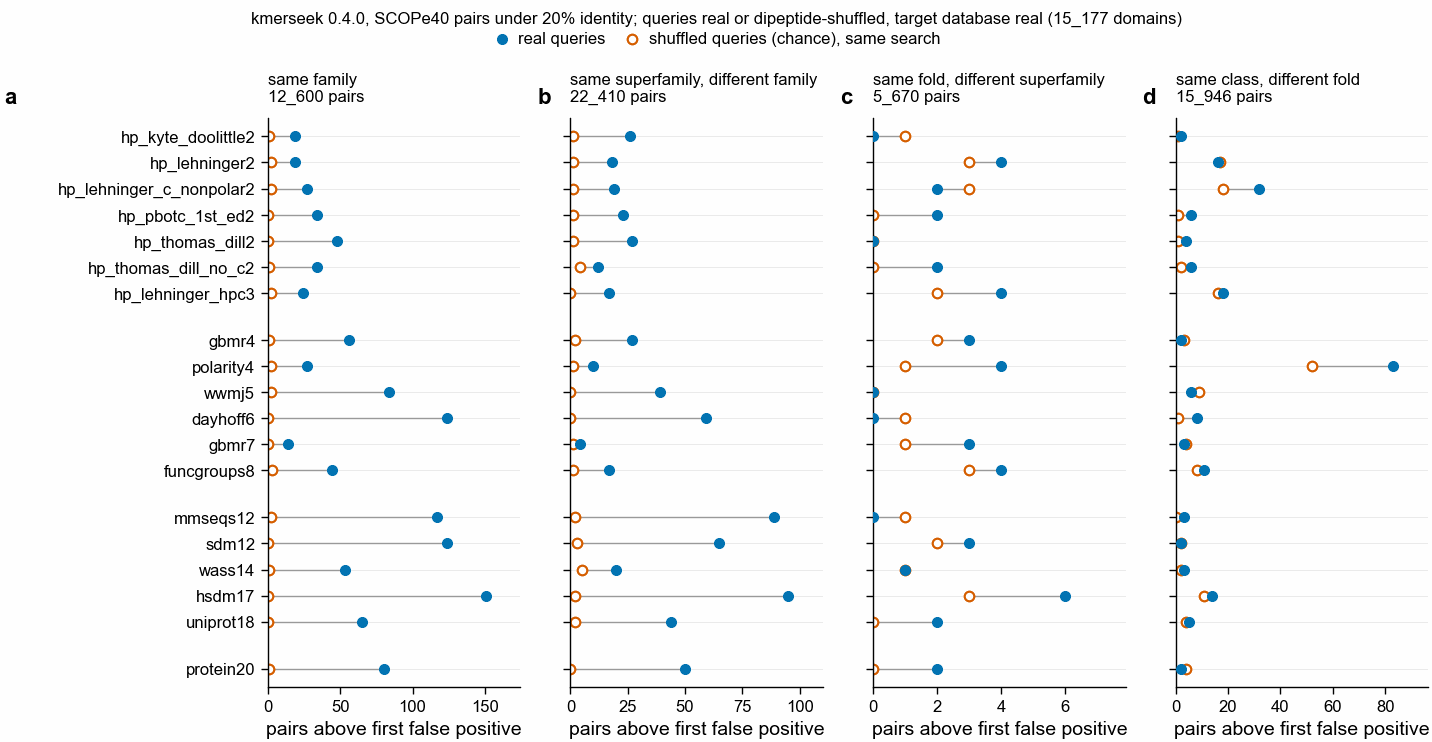

In [12]:
SHUF_BANDS = Path(
    os.environ.get(
        "NB277_SHUFFLED_BANDS",
        Path.home()
        / "data/scope/results-scope40-alphabet-ksize-v040-shuffled-k2-seed1/scope40_v040_identity_bands.tsv",
    )
)
print(SHUF_BANDS, "sha256", hashlib.sha256(SHUF_BANDS.read_bytes()).hexdigest())
shuf_raw = pl.read_csv(SHUF_BANDS, separator="\t", infer_schema_length=None)
print("queries:", shuf_raw["queries"].unique().to_list())
shuf = shuf_raw.filter(pl.col("status") == "ok").filter(
    (pl.col("setting").is_in(EXTENSION_SETTINGS) & (pl.col("score") == "region_evalue"))
    | ((pl.col("setting") == "exact") & (pl.col("score") == EXACT_SCORE))
)
BAND_KEY = ["alphabet", "ksize", "setting", "category", "identity_band"]
real_vs_shuf = bands2.select(
    BAND_KEY
    + [
        "n_pairs",
        pl.col("n_above_first_fp").alias("above_real"),
        pl.col("n_reported").alias("reported_real"),
    ]
).join(
    shuf.select(
        BAND_KEY
        + [
            pl.col("n_above_first_fp").alias("above_shuffled"),
            pl.col("n_reported").alias("reported_shuffled"),
        ]
    ),
    on=BAND_KEY,
    how="inner",
)
print(
    real_vs_shuf.select("alphabet", "ksize", "setting").unique().height,
    "searches in both runs",
)
u20 = real_vs_shuf.filter(pl.col("identity_band") == "0-20%")
print(
    "Under 20% identity, pairs above the first false positive, summed over all searches"
)
print(
    u20.group_by("category")
    .agg(
        pl.col("above_real").sum(),
        pl.col("above_shuffled").sum(),
        pl.col("reported_real").sum(),
        pl.col("reported_shuffled").sum(),
    )
    .sort("category")
)
pick = u20.sort("above_real", descending=True).group_by("alphabet", "category").head(1)
print("Each alphabet's search with the most real pairs above the first false positive")
print(
    pick.select(
        "category",
        "alphabet",
        "ksize",
        "setting",
        "n_pairs",
        "above_real",
        "above_shuffled",
    ).sort("category", "above_real", descending=[False, True])
)

fig, axs = pf.figure(pf.TWO_COLUMN_MM, 95, ncols=4, sharey=True)
for ax, cat in zip(axs, CATEGORY_LABEL):
    sub = pick.filter(pl.col("category") == cat)
    ys = [pos[a] for a in sub["alphabet"]]
    for r, y in zip(sub.iter_rows(named=True), ys):
        ax.plot(
            [r["above_shuffled"], r["above_real"]],
            [y, y],
            color=pf.GREY,
            lw=0.5,
            zorder=1,
        )
    ax.scatter(
        sub["above_real"],
        ys,
        s=12,
        color=pf.OKABE_ITO["blue"],
        zorder=3,
        label="real queries",
    )
    ax.scatter(
        sub["above_shuffled"],
        ys,
        s=12,
        facecolor="white",
        edgecolor=pf.OKABE_ITO["vermillion"],
        lw=0.8,
        zorder=2,
        label="shuffled queries (chance), same search",
    )
    alphabet_axis(ax, pos)
    ax.set_xlim(0, max(sub["above_real"].max(), sub["above_shuffled"].max()) * 1.15 + 1)
    ax.set_title(
        f"{CATEGORY_LABEL[cat]}\n{sub['n_pairs'][0]:_} pairs", fontsize=6, loc="left"
    )
    ax.set_xlabel("pairs above first false positive")
for ax, letter in zip(axs, "abcd"):
    pf.panel_label(ax, letter, dx_pt=-95 if letter == "a" else -12)
pf.shared_legend(
    fig,
    ncol=2,
    title="kmerseek 0.4.0, SCOPe40 pairs under 20% identity; queries real or "
    "dipeptide-shuffled, target database real (15_177 domains)",
)
pf.save(fig, FIG_DIR / f"{FIG_STEM}_shuffled_control_under_20", formats=("pdf", "png"))

## 9. Combining alphabets

Earlier tests on the Pfam domain benchmark found that no combination of alphabet-ksize pairs beat
the single best one (notebooks 261-264). Here the question is asked on SCOPe40: do different
alphabets find different true pairs, so that a combined list finds more than any one search?

**Data.** Eight searches, kept with their pair tables and combined in one step
(`bin/combine_alphabets.py`; head jobs 47932901 with real queries and 47932904 with the
dipeptide-shuffled queries of section 8, 2026-10-15): hsdm17 k5, mmseqs12 k6, dayhoff6 k8, sdm12
k7, protein20 k5, uniprot18 k5 and wwmj5 k9 at `c_max`, and hp_thomas_dill2 k18 at C = 2. These
were each alphabet's best at k_min or above, chosen before section 6 showed that smaller k does
better on the database scale.

**Methods**, all scored with the same code as a single search:

- *best of N*: a pair's smallest `region_evalue` over the eight searches;
- *rank fusion*: the sum over searches of 1 / (60 + the pair's rank in that search's list for
  the query), reciprocal rank fusion;
- *union upper limit*: a true pair counts if any search ranks it above that search's own first
  false positive. No single ranked list gives this; it is the most that combining these eight
  lists could find before the first false positive, so it has only a database-scale value.

All AUCs here are on the database scale (section 6). A shuffled-query value is the chance level
of the same method. Decision, written before the run: if the union upper limit is close to the
best single search, combining cannot help; if it is clearly higher, best of N or rank fusion is
worth keeping only if it beats the best single search at any k (0.149, hsdm17 k4, section 7) with
a shuffled-query value near zero.

real /Users/olga/data/scope/results-scope40-alphabet-ksize-v040-combine/scope40_v040_combined_auc.tsv sha256 81065533380b849f03df81d7cf0b0f1744ca14093f938ea26931b9254753b3a4
real /Users/olga/data/scope/results-scope40-alphabet-ksize-v040-combine/scope40_v040_combined_bands.tsv sha256 b1e6bdfec2e2e65594444aef5ee793ea4c15f96a6b167e64169ffa6aa94188be
shuffled /Users/olga/data/scope/results-scope40-alphabet-ksize-v040-combine-shuffled-k2-seed1/scope40_v040_combined_auc.tsv sha256 1c8d558cff2d0ad239d61241c10b7fb4ee17d8728fe6ea9c233567377404194c
shuffled /Users/olga/data/scope/results-scope40-alphabet-ksize-v040-combine-shuffled-k2-seed1/scope40_v040_combined_bands.tsv sha256 f80458b38b3d025db390a417aee235b4c4944a1832e190c605017f065b805306
Database-scale AUC, real and shuffled queries
shape: (11, 5)
┌───────────────────────────────┬───────────────────┬────────────────────────┬────────────────────────────┬─────────────────────────────────┐
│ method                        ┆ auc_ref_db_family ┆

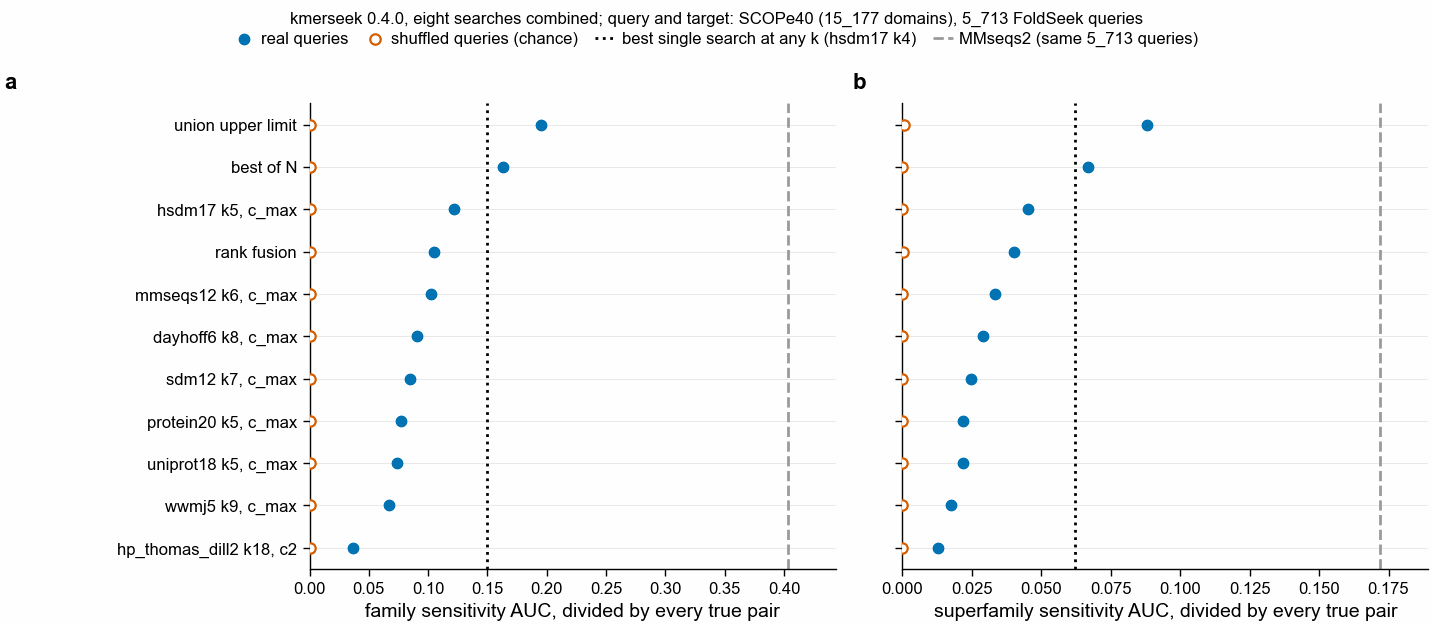

In [13]:
COMBINE_DIRS = {
    "real": Path(
        os.environ.get(
            "NB277_COMBINE_DIR",
            Path.home() / "data/scope/results-scope40-alphabet-ksize-v040-combine",
        )
    ),
    "shuffled": Path(
        os.environ.get(
            "NB277_COMBINE_SHUFFLED_DIR",
            Path.home()
            / "data/scope/results-scope40-alphabet-ksize-v040-combine-shuffled-k2-seed1",
        )
    ),
}
comb = {}
for queries, d in COMBINE_DIRS.items():
    for name in ("scope40_v040_combined_auc.tsv", "scope40_v040_combined_bands.tsv"):
        path = d / name
        print(queries, path, "sha256", hashlib.sha256(path.read_bytes()).hexdigest())
        comb[(queries, name)] = pl.read_csv(
            path, separator="\t", infer_schema_length=None
        ).filter(pl.col("status") == "ok")
comb_auc = (
    comb[("real", "scope40_v040_combined_auc.tsv")]
    .select("method", "level", "auc_ref_db")
    .join(
        comb[("shuffled", "scope40_v040_combined_auc.tsv")].select(
            "method", "level", pl.col("auc_ref_db").alias("auc_ref_db_shuffled")
        ),
        on=["method", "level"],
    )
)
best_any_k = {
    lv: best_db.filter(pl.col("level") == lv)
    .sort("auc_ref_db", descending=True)
    .row(0, named=True)
    for lv in ALL_LEVELS
}
print("Database-scale AUC, real and shuffled queries")
with pl.Config(float_precision=5):
    print(
        comb_auc.filter(pl.col("level").is_in(["family", "superfamily"]))
        .pivot(on="level", index="method", values=["auc_ref_db", "auc_ref_db_shuffled"])
        .sort("auc_ref_db_family", descending=True)
    )
for lv in ["family", "superfamily"]:
    r = best_any_k[lv]
    print(
        f"{lv}: best single search at any k {r['alphabet']} k{r['ksize']} {r['setting']} {r['auc_ref_db']:.4f}; "
        f"MMseqs2 {TOOL_AUC[('MMseqs2', lv)]:.4f}"
    )
comb_bands = (
    comb[("real", "scope40_v040_combined_bands.tsv")]
    .select("method", "category", "identity_band", "n_pairs", "n_above_first_fp")
    .join(
        comb[("shuffled", "scope40_v040_combined_bands.tsv")].select(
            "method",
            "category",
            "identity_band",
            pl.col("n_above_first_fp").alias("n_above_first_fp_shuffled"),
        ),
        on=["method", "category", "identity_band"],
    )
)
print("Under 20% identity, pairs above the first false positive: real (shuffled)")
print(
    comb_bands.filter(pl.col("identity_band") == "0-20%")
    .with_columns(
        pl.format("{} ({})", "n_above_first_fp", "n_above_first_fp_shuffled").alias(
            "real_shuffled"
        )
    )
    .pivot(on="category", index="method", values="real_shuffled")
    .select(["method"] + list(CATEGORY_LABEL))
)

METHOD_LABEL = {
    "union_upper_limit": "union upper limit",
    "best_of_n": "best of N",
    "rank_fusion": "rank fusion",
}
order = (
    comb_auc.filter(pl.col("level") == "family")
    .sort("auc_ref_db", descending=True)["method"]
    .to_list()
)
mpos = {m: i for i, m in enumerate(order)}
fig, axs = pf.figure(pf.TWO_COLUMN_MM, 80, ncols=2, sharey=True)
for ax, level in zip(axs, ["family", "superfamily"]):
    sub = comb_auc.filter(pl.col("level") == level)
    ys = [mpos[m] for m in sub["method"]]
    ax.scatter(
        sub["auc_ref_db"],
        ys,
        s=14,
        color=pf.OKABE_ITO["blue"],
        zorder=3,
        label="real queries",
    )
    ax.scatter(
        sub["auc_ref_db_shuffled"],
        ys,
        s=14,
        facecolor="white",
        edgecolor=pf.OKABE_ITO["vermillion"],
        lw=0.8,
        zorder=3,
        label="shuffled queries (chance)",
    )
    ax.axvline(
        best_any_k[level]["auc_ref_db"],
        color=pf.OKABE_ITO["black"],
        ls=":",
        lw=1,
        label="best single search at any k (hsdm17 k4)",
    )
    ax.axvline(
        TOOL_AUC[("MMseqs2", level)],
        label="MMseqs2 (same 5_713 queries)",
        **TOOL_STYLE["MMseqs2"],
    )
    ax.set_yticks(
        range(len(order)),
        [
            METHOD_LABEL.get(
                m, re.sub(r"^single:(.+)\.k(\d+)\.(.+)$", r"\1 k\2, \3", m)
            )
            for m in order
        ],
    )
    ax.set_ylim(len(order) - 0.5, -0.5)
    for y in range(len(order)):
        ax.axhline(y, color="0.9", lw=0.3, zorder=0)
    ax.set_xlim(0, TOOL_AUC[("MMseqs2", level)] * 1.1)
    ax.set_xlabel(f"{level} sensitivity AUC, divided by every true pair")
pf.panel_label(axs[0], "a", dx_pt=-110)
pf.panel_label(axs[1], "b")
pf.shared_legend(
    fig,
    ncol=4,
    title="kmerseek 0.4.0, eight searches combined; query and target: SCOPe40 "
    "(15_177 domains), 5_713 FoldSeek queries",
)
pf.save(fig, FIG_DIR / f"{FIG_STEM}_combined_alphabets", formats=("pdf", "png"))

## 10. Answers to the four decisions

The numbers each decision rests on, from the tables and figures of sections 1-9.

In [14]:
fam_best = best.filter(pl.col("level") == "family")
top_col = by_score.filter(pl.col("level") == "family").row(0, named=True)
print(
    f"1. Score column: {top_col['score']}, median family AUC {top_col['median_auc']:.3f} over "
    f"{top_col['n_searches']} extension searches; median tie gap {top_col['median_tie_gap']:.3f}, "
    f"largest {top_col['max_tie_gap']:.3f}"
)
for s_, g in fam_best.group_by("setting"):
    print(
        f"2. Best family AUC with {s_[0]} for {g.height} of {fam_best.height} alphabets: {', '.join(g['alphabet'])}"
    )
n_kmin = int(fam_best["best_k_is_k_min"].sum())
near = fam_best.filter(pl.col("ksize") <= pl.col("k_min") + 1).height
print(
    f"3. Best k is the alphabet's k_min for {n_kmin} of {fam_best.height} alphabets; "
    f"k_min or k_min + 1 for {near} of {fam_best.height}"
)
for metric, label in (
    ("auc_ref", "reported-pairs scale"),
    ("auc_ref_db", "database scale"),
):
    for lv, g in compare[metric].group_by("level", maintain_order=True):
        print(
            f"3. Below k_min, {label} ({lv[0]}): better for {int((g['change'] > 0).sum())} of {g.height} "
            f"alphabets, largest change {g['change'].max():+.4f}"
        )
hp_best = (
    fam_best.filter(pl.col("alphabet").str.starts_with("hp_"))
    .sort("auc_ref", descending=True)
    .row(0, named=True)
)
mm = TOOL_AUC[("MMseqs2", "family")]
print(
    f"4. Best HP family AUC: {hp_best['alphabet']} k{hp_best['ksize']} {hp_best['setting']} = "
    f"{hp_best['auc_ref']:.3f}; MMseqs2 = {mm:.3f}; half of MMseqs2 = {mm / 2:.3f}; "
    f"HP reaches half: {hp_best['auc_ref'] >= mm / 2}"
)
db_fam = best_db.filter(pl.col("level") == "family")
hp_db = (
    db_fam.filter(pl.col("alphabet").str.starts_with("hp_"))
    .sort("auc_ref_db", descending=True)
    .row(0, named=True)
)
top_db = db_fam.sort("auc_ref_db", descending=True).row(0, named=True)
print(
    f"4. On FoldSeek's scale (section 7): best kmerseek {top_db['alphabet']} k{top_db['ksize']} = "
    f"{top_db['auc_ref_db']:.3f} ({top_db['auc_ref_db'] / mm:.0%} of MMseqs2); best HP {hp_db['alphabet']} "
    f"k{hp_db['ksize']} = {hp_db['auc_ref_db']:.3f} ({hp_db['auc_ref_db'] / mm:.0%} of MMseqs2)"
)
for cat in CATEGORY_LABEL:
    sub = under20.filter(pl.col("category") == cat).sort(
        "share_above_first_fp", descending=True
    )
    top = sub.row(0, named=True)
    hp_top = sub.filter(pl.col("alphabet").str.starts_with("hp_")).row(0, named=True)
    ref = sub.filter(pl.col("alphabet").is_in(["protein20", "mmseqs12", "sdm12"]))
    shuf_top = (
        pick.filter(pl.col("category") == cat)
        .sort("above_real", descending=True)
        .row(0, named=True)
    )
    print(
        f"4. Under 20% identity, {CATEGORY_LABEL[cat]}: of the 146 searches also run on shuffled queries, "
        f"the most real pairs: {shuf_top['alphabet']} k{shuf_top['ksize']} {shuf_top['setting']}, "
        f"{shuf_top['above_real']} real, {shuf_top['above_shuffled']} shuffled"
    )
    print(
        f"4. Under 20% identity, {CATEGORY_LABEL[cat]}: best {top['alphabet']} {top['n_above_first_fp']} of "
        f"{top['n_pairs']} pairs; best HP {hp_top['alphabet']} {hp_top['n_above_first_fp']}; "
        + ", ".join(
            f"{a} {n}"
            for a, n in ref.sort("alphabet")
            .select("alphabet", "n_above_first_fp")
            .iter_rows()
        )
    )

1. Score column: region_evalue, median family AUC 0.062 over 659 extension searches; median tie gap 0.000, largest 0.159
2. Best family AUC with c2 for 6 of 19 alphabets: hp_thomas_dill2, funcgroups8, hp_thomas_dill_no_c2, hp_kyte_doolittle2, hp_lehninger2, gbmr7
2. Best family AUC with c_max for 13 of 19 alphabets: mmseqs12, sdm12, protein20, hsdm17, uniprot18, dayhoff6, wwmj5, wass14, gbmr4, hp_pbotc_1st_ed2, polarity4, hp_lehninger_c_nonpolar2, hp_lehninger_hpc3
3. Best k is the alphabet's k_min for 10 of 19 alphabets; k_min or k_min + 1 for 17 of 19
3. Below k_min, reported-pairs scale (family): better for 0 of 16 alphabets, largest change -0.0008
3. Below k_min, reported-pairs scale (fold): better for 1 of 16 alphabets, largest change +0.0002
3. Below k_min, reported-pairs scale (superfamily): better for 2 of 16 alphabets, largest change +0.0032
3. Below k_min, database scale (family): better for 16 of 16 alphabets, largest change +0.0627
3. Below k_min, database scale (fold): bet

## Summary and conclusions

Every number is printed by a cell above. AUC is family-level sensitivity over FoldSeek's 5_713
SCOPe40 queries (0 to 1, higher is better), with a tied score counted against kmerseek.
On the same queries FoldSeek reaches 0.817 and MMseqs2 0.403. Items 1-3 and 6 compare kmerseek
searches with each other and use the reported-pairs scale; item 4 compares with the two tools
and uses theirs.

1. **Rank SCOPe40 hits by `region_evalue`.** It has the highest median family AUC over the 659
   extension searches that returned hits (0.062), and ties do not move it (median gap 0).
   `region_ka_bits` is next (0.060). The query-level columns (`containment`,
   `query_poisson_pvalue`) reach at most 0.146. `query_tfidf` is the same for every hit of a
   query, so its AUC is set by the tie order (gap up to 0.71); it cannot rank hits.
2. **Use C = c_max for the 12-20 letter alphabets.** c_max gives the best family AUC for 13 of
   19 alphabets, including every 12-20 letter alphabet. For the 2-3 letter HP alphabets c_max and
   C = 2 differ by at most 0.004. c_min is the worst setting: it is refused on 119 of 229
   alphabet-ksize pairs and never beats exact matching (0 of 110 pairs).
3. **On the scale FoldSeek and MMseqs2 use, the best k is below k_min, and may be lower still.**
   On the reported-pairs scale k_min is the peak: below it, the best family AUC is lower for 16
   of 16 alphabets. On the database scale (section 6) it is higher for 16 of 16, at family,
   superfamily and fold level: sdm12 from 0.085 at k7 to 0.148 at k5, protein20 from 0.077 at k5
   to 0.127 at k4. A smaller k reports many more pairs, so more true pairs land above the first
   false positive even though each list is noisier. Several of these best k-sizes sit at the
   15-bit floor of the follow-up run, so the peak on this scale may be lower. Memory rises
   steeply there (dayhoff6 k6 peaked at 82 GB). *Decision: compare with other tools at k below
   notebook 274's k_min; going lower needs memory planned search by search.*
4. **On the scale FoldSeek and MMseqs2 use, kmerseek reaches about a third of MMseqs2, and HP
   about an eighth.** Best family AUC: 0.149 (hsdm17 k4, C = c_max), 37% of MMseqs2's 0.403;
   protein20 0.127 (k4, 32%); the best HP alphabet, hp_thomas_dill2, 0.048 (k16, 12%).
   Superfamily: 0.062 against 0.172. Fold: 0.0003 against MMseqs2's 0.0008. Earlier versions
   of this summary said "half to three quarters of MMseqs2" (comparing the reported-pairs scale
   with the tools) and then "about a quarter" (before the run below k_min); both are replaced.
5. **Under 20% identity kmerseek ranks almost no pair above the first false positive, at any
   level.** At each alphabet's best k and setting (section 7), at most 199 of the 12_600
   same-family pairs (1.6%, sdm12 k5), 129 of the 22_410 same-superfamily pairs (0.58%, mmseqs12
   k5) and 7 of the 5_670 same-fold pairs (hsdm17). HP is not ahead at family (best 58) or
   superfamily (best 33). At class level (same class, different fold; 15_946 pairs) the coarse
   alphabets lead: polarity4 83 pairs, wwmj5 53, hp_lehninger_c_nonpolar2 44, against 5 to 19
   for protein20, mmseqs12 and sdm12. The shuffled-query control (section 8, on the 146 searches
   that also ran with shuffled queries) removes most of that lead: polarity4 gives 52 with
   shuffled queries, hp_lehninger_c_nonpolar2 18 and hp_lehninger2 17 (16 real). Summed over
   those searches, class pairs are 552 real against 435 shuffled and fold pairs 95 against 73,
   while family pairs are 4_971 against 210 and superfamily pairs 2_717 against 268. Under 20%
   identity kmerseek finds a few real family and superfamily pairs; at fold and class level it is
   close to chance, and the coarse alphabets' class lead comes from composition, not residue
   order. *Decision: SCOPe40 does not support the HP case at any level.*
6. **Extension helps at c_opt, c_max and C = 2.** It beats exact matching on 140 of 140 pairs at
   c_max, 142 of 151 at C = 2 and 99 of 117 at c_opt (section 5).
7. **Combining alphabets helps on SCOPe40: best of N beats every single search.** Taking each
   pair's smallest E-value over eight searches (section 9) gives a family AUC of 0.163 and a
   superfamily AUC of 0.067 on the database scale, against 0.149 and 0.062 for the best single
   search at any k (hsdm17 k4) and 0.122 and 0.045 for the best of the eight. On shuffled queries
   best of N stays at 0.00004, so it adds almost no chance pairs. Under 20% identity it ranks 232
   same-family pairs above the first false positive (shuffled: 0), against 151 for hsdm17 k5.
   The union upper limit is 0.195 (family), so a better way of merging these lists could find
   more. Rank fusion (0.105) does worse than the best single search. This differs from the Pfam
   domain benchmark, where no combination won (notebooks 261-264). These eight searches are at
   k_min or above; section 6 shows the best single searches are below k_min, so the next test
   combines those. *Decision: keep best of N; drop rank fusion.*